# Realistic Model Demo

In [116]:
import numpy as np
from numpy.polynomial.legendre import leggauss
from scipy.interpolate import BSpline
from scipy.integrate import quad, fixed_quad
from scipy.linalg import cho_factor, cho_solve
from scipy.optimize import minimize
import pandas as pd
from matplotlib import pyplot as plt

import lhapdf
import pineappl
from pineappl.convolutions import Conv, ConvType
from validphys.api import API
from validphys.pineparser import pineappl_reader
from validphys.fkparser import load_fktable
from validphys.loader import Loader

import json
import pickle
import yaml

In [2]:
# read Table 1
df = pd.read_csv("HEPData-ins1377206-v1-csv/Table1.csv")

In [3]:
df

,Q**2 [GEV**2],XB,"sigma_{r,NC} +",stat +,stat -,"sys,uncor +","sys,uncor -","sys,cor +","sys,cor -","sys,rel +",...,"sys,had +","sys,had -","sys,1 +","sys,1 -","sys,2 +","sys,2 -","sys,3 +","sys,3 -","sys,4 +","sys,4 -"
0,0.15,0.000005,0.185,3.79%,-3.79%,1.5%,-1.5%,3.62%,-3.62%,1.39%,...,-0.21%,0.21%,-0.17%,0.17%,-0.01%,0.01%,0.0%,-0.0%,0.01%,-0.01%
1,0.20,0.000007,0.227,1.65%,-1.65%,0.78%,-0.78%,1.7%,-1.7%,0.86%,...,0.0%,-0.0%,0.0%,-0.0%,0.0%,-0.0%,0.0%,-0.0%,0.01%,-0.01%
2,0.20,0.000008,0.223,1.61%,-1.61%,0.61%,-0.61%,2.19%,-2.19%,1.06%,...,-0.26%,0.26%,-0.06%,0.06%,0.0%,-0.0%,0.0%,-0.0%,0.0%,-0.0%
3,0.20,0.000011,0.208,2.79%,-2.79%,1.5%,-1.5%,2.83%,-2.83%,1.01%,...,-0.08%,0.08%,-0.18%,0.18%,0.0%,-0.0%,0.0%,-0.0%,0.01%,-0.01%
4,0.20,0.000040,0.211,14.93%,-14.93%,11.96%,-11.96%,5.18%,-5.18%,0.33%,...,2.93%,-2.93%,1.57%,-1.57%,-0.03%,0.03%,-0.02%,0.02%,0.15%,-0.15%
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
480,20000.00,0.250000,0.126,11.42%,-11.42%,3.08%,-3.08%,1.33%,-1.33%,0.64%,...,-0.06%,0.06%,0.01%,-0.01%,-0.05%,0.05%,-0.1%,0.1%,0.19%,-0.19%
481,20000.00,0.400000,0.078,15.35%,-15.35%,5.55%,-5.55%,1.22%,-1.22%,-0.22%,...,-0.02%,0.02%,0.0%,-0.0%,-0.06%,0.06%,0.1%,-0.1%,0.49%,-0.49%
482,20000.00,0.650000,0.012,32.5%,-32.5%,13.66%,-13.66%,2.15%,-2.15%,1.84%,...,0.09%,-0.09%,0.01%,-0.01%,-0.08%,0.08%,-0.17%,0.17%,0.59%,-0.59%
483,30000.00,0.400000,0.060,24.46%,-24.46%,2.34%,-2.34%,4.42%,-4.42%,0.34%,...,-0.18%,0.18%,0.01%,-0.01%,-0.06%,0.06%,0.16%,-0.16%,0.43%,-0.43%


## Model Specification

In [117]:
# suppressing factor
Lambda = 500
# range of Q2
Q2_min = 20
Q2_max = 200

def klin(z, Lambda=Lambda, Q2_min=Q2_min, Q2_max=Q2_max):
    z = np.asarray(z, dtype=float)
    return 1/(Lambda**2) * ((z - Q2_min)**2) / ((Q2_max - Q2_min)**2)

def kquad(z, Lambda=Lambda, Q2_min=Q2_min, Q2_max=Q2_max):
    z = np.asarray(z, dtype=float)
    return 1/(Lambda**4) * ((z - Q2_min)**2) / ((Q2_max - Q2_min)**2)

In [118]:
def alpha_s(Q2, Q2_0=20.0):
    # for simplicity, we use a constant αs, but it can be made Q2-dependent if desired.
    # In LHAPDF, you can get αs(Q2) from the PDF set, e.g., pdf.alphasQ2(Q2).
    return 0.2

def sigma_T3_NLO(x, Q2, alpha_s, gV, CF=4/3):
    """
    This function returns only the NLO term, evaluated pointwise for x in (0,1).

    Parameters
    ----------
    x : float or array-like
        Bjorken x values. Should satisfy 0 < x < 1 (and not exactly 1).
    Q2 : float
        Q^2 (kept for signature consistency; alpha_s can be a function of Q2).
    alpha_s : float or callable
        Either a number alpha_s(Q^2) or a function alpha_s(Q2)->float.
    gV : float
        g_V
    CF : float, default 4/3
        C_F

    Returns
    -------
    NLO : np.ndarray
        NLO (non-delta) contribution evaluated at x.
    """
    x = np.asarray(x, dtype=float)

    # get αs(Q^2)
    a = alpha_s(Q2) if callable(alpha_s) else float(alpha_s)

    # safe mask: avoid x<=0, x>=1, and x==1 singularity
    nlo = np.full_like(x, np.nan, dtype=float)
    mask = (x > 0.0) & (x < 1.0) & (x != 1.0)

    xm = x[mask]
    term = ((1.0 + xm**2) / (2.0 * (1.0 - xm))) * (np.log((1.0 - xm) / xm) - 3.0/4.0) - (1.0 + xm)

    nlo[mask] = (gV**2) * (CF * a / (2.0 * np.pi)) * term
    return nlo

In [119]:
# Build B-spline basis on [0,1]
def bspline_basis(degree, M, a, b):
    """
    Parameters
    ----------
    degree: degree of B-splines
    M: number of basis functions
    a, b: interval endpoints
    """

    # knots
    n_internal = M - degree - 1
    if n_internal > 0:
        inner_knots = np.linspace(a, b, n_internal + 2)[1:-1]
    else:
        inner_knots = np.array([])
    knots = np.r_[np.repeat(a, degree + 1), inner_knots, np.repeat(b, degree + 1)]
    #print("knots: ", knots)

    # basis functions
    I = np.eye(M)
    B = [BSpline(knots, I[m], degree, extrapolate=False) for m in range(M)]
    return B


# ----------------------------
# Helpers for (x,Q2) pairs
# ----------------------------
def _as_pairs(xQ2):
    """
    Normalize input into an (n,2) float array of (x, Q2).
    Accepts:
      - array-like shape (n,2)
      - tuple/list (x_array, Q2_array) with same length
    """
    if isinstance(xQ2, (tuple, list)) and len(xQ2) == 2 and np.ndim(xQ2[0]) > 0:
        x = np.asarray(xQ2[0], dtype=float)
        Q2 = np.asarray(xQ2[1], dtype=float)
        if x.shape != Q2.shape:
            raise ValueError(f"x and Q2 must have same shape, got {x.shape} vs {Q2.shape}")
        return np.column_stack([x.ravel(), Q2.ravel()]).astype(float)

    arr = np.asarray(xQ2, dtype=float)
    if arr.ndim != 2 or arr.shape[1] != 2:
        raise ValueError(f"xQ2 must have shape (n,2), got {arr.shape}")
    return arr


def _validate_x(x, idx=None):
    if x <= 0.0:
        where = f" at index {idx}" if idx is not None else ""
        raise ValueError(f"x must be in (0,1], got x={x}{where}.")


def build_f_design_matrix(
    xQ2,
    B,
    sigma_NLO,          # sigma_NLO(z, Q2) -> NLO part (no delta function)
    gV,        
    n_quad=1000,
):
    """
    Build A with entries
        A[r,k] = (gV**2)*x_r*B_k(x) + ∫_{x_r}^1 sigma_NLO(x_r/y, Q2_r) * B_k(y) dy

    
    Parameters
    ----------
    xQ2: (n,2) array of (x,Q2) pairs
    B: list of m basis functions, each B_k is a callable B_k(y)
    sigma_NLO: callable sigma_NLO(z, Q2) that can be vectorized in z
    gV: float, coupling constant
    n_quad: number of quadrature points for numerical integration        

    Returns
    -------
    A : ndarray, shape (n, m)
        Design matrix.
    """
    xQ2 = _as_pairs(xQ2)
    n_pts = xQ2.shape[0]
    m = len(B)

    nodes, weights = leggauss(n_quad)

    A = np.zeros((n_pts, m), dtype=float)

    for r, (x, Q2) in enumerate(xQ2):
        _validate_x(x, idx=r)

        # ----- LO part: dc * x * B_k(x) -----
        B_at_x = np.array([Bk(x) for Bk in B], dtype=float)
        A[r, :] += (gV**2) * x * B_at_x

        # ----- NLO part integral over y in [x, 1] -----
        if x >= 1.0:
            continue

        a, b = x, 1.0
        y = 0.5 * (b - a) * nodes + 0.5 * (b + a)
        jac = 0.5 * (b - a)

        z = x / y
        sig = sigma_NLO(z, Q2)  # shape (n_quad,)

        # evaluate all basis functions on y
        B_y = np.vstack([Bk(y) for Bk in B])  # shape (m, n_quad)

        # A[r,k] += ∫ sigma_NLO(z,Q2) * B_k(y) dy
        A[r, :] += jac * (B_y * (weights * sig)).sum(axis=1)

    return A



def build_yf_design_matrix(
    xQ2,
    B,
    sigma_NLO,          # sigma_NLO(z, Q2) -> NLO part (no delta function)
    gV,
    n_quad=1000,
):
    """
    Build A for the parameterization g(y) = y f(y) = sum_k theta_k B_k(y),
    so that f(y) = g(y)/y.

    Then the forward model is

        T(x, Q2)
        = (gV**2) * f(x) * x + ∫_x^1 sigma_NLO(x/y, Q2) f(y) dy
        = (gV**2) * g(x) + ∫_x^1 sigma_NLO(x/y, Q2) * g(y)/y dy

    and since g(y) = sum_k theta_k B_k(y),

        A[r,k] = (gV**2) * B_k(x_r)
                 + ∫_{x_r}^1 sigma_NLO(x_r / y, Q2_r) * B_k(y)/y dy

    Parameters
    ----------
    xQ2 : (n,2) array
        Array of (x, Q2) pairs.
    B : list of callables
        Basis functions B_k(y).
    sigma_NLO : callable
        Function sigma_NLO(z, Q2), vectorized in z.
    gV : float
        Coupling constant.
    n_quad : int
        Number of Gauss-Legendre quadrature points.

    Returns
    -------
    A : ndarray, shape (n, m)
        Design matrix.
    """
    xQ2 = _as_pairs(xQ2)
    n_pts = xQ2.shape[0]
    m = len(B)

    nodes, weights = leggauss(n_quad)
    A = np.zeros((n_pts, m), dtype=float)

    for r, (x, Q2) in enumerate(xQ2):
        _validate_x(x, idx=r)

        # ----- LO part: (gV**2) * B_k(x) -----
        B_at_x = np.array([Bk(x) for Bk in B], dtype=float)
        A[r, :] += (gV**2) * B_at_x

        # ----- NLO part: ∫_x^1 sigma_NLO(x/y, Q2) * B_k(y)/y dy -----
        if x >= 1.0:
            continue

        a, b = x, 1.0
        y = 0.5 * (b - a) * nodes + 0.5 * (b + a)
        jac = 0.5 * (b - a)

        z = x / y
        sig = sigma_NLO(z, Q2)  # shape (n_quad,)

        # evaluate all basis functions on y
        B_y = np.vstack([Bk(y) for Bk in B])  # shape (m, n_quad)

        A[r, :] += jac * (B_y * (weights * sig / y)).sum(axis=1)

    return A


def v_c(c, xQ2, klin=klin, kquad=kquad):
    xQ2 = _as_pairs(xQ2)
    Q2 = xQ2[:, 1]
    return 1.0 + klin(Q2) * c + kquad(Q2) * (c**2)

def v_prime_c(c, xQ2, klin=klin, kquad=kquad):
    xQ2 = _as_pairs(xQ2)
    Q2 = xQ2[:, 1]
    return klin(Q2) + 2.0 * c * kquad(Q2)


def T_sm(
    xQ2,
    f,                  # f(y) -> array
    sigma_NLO,          # sigma_NLO(z, Q2) -> array (NLO part only)
    gV,
    n_quad=1000,
):
    """
    For each pair (x,Q2):
      T(x,Q2) = (gV**2) * x * f(x) + ∫_x^1 f(y) * sigma_NLO(x/y, Q2) dy


    Parameters
    ----------
    xQ2      : (n,2) array of (x,Q2) pairs
    f        : callable f(y) -> array same shape as y
    sigma_NLO : callable sigma_NLO(z, Q2) -> array same shape as z
    gV      : float, coupling constant
    n_quad  : int, number of Gauss-Legendre points for numerical integration

    Returns
    -------
    T_vec    : (n,) array of T_SM values
    """
    xQ2 = _as_pairs(xQ2)
    n_pts = xQ2.shape[0]

    nodes, weights = np.polynomial.legendre.leggauss(n_quad)
    T_vec = np.zeros(n_pts, dtype=float)

    for r, (x, Q2) in enumerate(xQ2):
        _validate_x(x, idx=r)

        # ----- LO contribution: dc * x * f(x) -----
        T_LO = (gV**2) * x * float(np.asarray(f(x)))

        if x >= 1.0:
            T_vec[r] = T_LO
            continue

        # ----- NLO contribution -----
        a, b = x, 1.0
        y = 0.5 * (b - a) * nodes + 0.5 * (b + a)
        jac = 0.5 * (b - a)

        z = x / y
        integrand = f(y) * sigma_NLO(x=z, Q2=Q2)

        T_NLO = jac * np.sum(weights * integrand)

        T_vec[r] = T_LO + T_NLO

    return T_vec


def T_sm_basis(A, beta):
    return A @ beta

def gaussian_mean_basis(c, beta, A, xQ2, klin=klin, kquad=kquad):
    v = v_c(c, xQ2, klin=klin, kquad=kquad)        
    T = T_sm_basis(A, beta)
    return v * T

def gaussian_mean(c, T, xQ2, klin=klin, kquad=kquad):
    v = v_c(c, xQ2, klin=klin, kquad=kquad)
    return v * T

def build_K_matrix(c, A, xQ2, klin=klin, kquad=kquad):
    v = v_c(c, xQ2, klin=klin, kquad=kquad)
    return np.diag(v) @ A

def build_K_prime_matrix(c, A, xQ2, klin=klin, kquad=kquad):
    v_prime = v_prime_c(c, xQ2, klin=klin, kquad=kquad)
    return np.diag(v_prime) @ A

In [120]:
# Here, we define the functions based on FK tables and datasets, and build the design matrix A as well as theory predictions.
def build_f_design_matrix_FK(B, W, grid):
    """
    Build the design matrix A using FK tables, where the convolution is represented as a matrix multiplication with W.

    Parameters
    ----------
    B : list of m basis functions, each B_k is a callable B_k(y)
    W : (N_data, N_grid) matrix from FK table representing the convolution
    grid, (N_grid) array of y values corresponding to the columns of W

    Returns
    -------
    A : (N_data, m) array
        Design matrix where A[r,k] = ∫ sigma(x_r/y, Q2_r) * B_k(y) dy = W @ B_grid.T.
    """

    # Evaluate basis functions on the grid points corresponding to W
    B_grid = np.vstack([Bk(grid) for Bk in B])  # shape (m, n_grid)

    # The design matrix A is then given by the convolution of W with the basis functions evaluated on the grid
    A = W @ B_grid.T  # shape (N_data, m)

    return A

def build_yf_design_matrix_FK(B, W, grid):
    """
    Build the design matrix A for the parameterization g(y) = y f(y) = sum_k theta_k B_k(y),
    using FK tables.

    Parameters
    ----------
    B : list of m basis functions, each B_k is a callable B_k(y)
    W : (N_data, N_grid) matrix from FK table representing the convolution with f(y)
    grid, (N_grid) array of y values corresponding to the columns of W

    Returns
    -------
    A : (N_data, m) array
        Design matrix where A[r,k] = ∫ sigma(x_r/y, Q2_r) * B_k(y) dy = W @ (B_grid.T / grid).
    """

    # Evaluate basis functions on the grid points corresponding to W
    B_grid = np.vstack([Bk(grid) for Bk in B])  # shape (m, n_grid)

    # The design matrix A is then given by the convolution of W with the basis functions evaluated on the grid, divided by y
    A = W @ (B_grid.T / grid)  # shape (N_data, m)

    return A

def T_sm_FK(f, W, grid):
    """
    Compute T_SM using FK tables, where f is the PDF function and W is the convolution matrix.
    
    Parameters
    ----------
    f : callable
        The PDF function
    W : (N_data, N_grid) matrix from FK table representing the convolution
    grid : (N_grid) array of y values corresponding to the columns of W

    Returns
    -------
    T_vec : (N_data) array
        The standard model predictions.
    """
    # Evaluate PDF on the grid
    f_grid = f(grid)  # shape (N_grid,)

    # Compute T_vec
    T_vec = W @ f_grid  # shape (N_data,)

    return T_vec

### Likelihood and Estimation Functions

In [121]:
# Negative log-likelihood and gradient
def make_nll_and_grad(D, A, v, v_prime, xQ2, Sigma=None):
    """
    D     : (N,) data vector
    A     : (N, M) matrix from T(f) (T(f) = A @ beta)
    v     : callable     v(c) returns (N,) vector
    v_prime: callable    v_prime(c) returns (N,) vector (derivative of v)
    xQ2: (n, 2) array of (x,Q2) pairs
    Sigma : (N, N) known covariance (default None; identity matrix)
    """
    N, M = A.shape

    if Sigma is not None:
        # Cholesky factorization of Sigma
        cF, lower = cho_factor(Sigma, check_finite=False)
        def Sigma_inv(v):    # Sigma^{-1} v
            return cho_solve((cF, lower), v, check_finite=False)
    else:
        def Sigma_inv(v):
            return v


    def nll(theta):
        beta = theta[:M]
        c = theta[-1]
        vc = v(c, xQ2=xQ2)
        mu = vc * (A @ beta)
        r = D - mu
        #loss = 0.5 * r @ r
        loss = 0.5 * r @ Sigma_inv(r)

        return loss

    def grad(theta):
        beta = theta[:M]
        c = theta[-1]

        vc = v(c, xQ2=xQ2)
        dv = v_prime(c, xQ2=xQ2)
        mu = vc * (A @ beta)         
        r = D - mu
        Sigma_inv_r = Sigma_inv(r)

        # d(NLL)/d beta = - (diag(v(c)) A)^T Sigma^{-1} r
        g_beta = - ((vc[:, None] * A).T @ Sigma_inv_r)

        # d(NLL)/d c = - (dv(c) \odot (A beta))^T Sigma^{-1} r
        g_c = - (dv * (A @ beta)).T @ Sigma_inv_r

        return np.r_[g_beta, g_c]

    return nll, grad


def fit_beta_c(D, A, v, v_prime, w_norm, xQ2, Sigma=None, beta0=None, c0=0.0,
               nonneg_beta=False, return_history=False, opt_method="SLSQP"):
    """
    Fit parameters beta and c by joint minimization of the negative log-likelihood.
    
    D     : (N,) data vector
    A     : (N, M) matrix from T(f) (T(f) = A @ beta)
    v     : callable     v(c) returns (N,) vector
    v_prime: callable    v_prime(c) returns (N,) vector (derivative of v)
    w_norm: (M,) normalization weights, int B_m(y) dy
    xQ2: (N, 2) array of (x,Q2) pairs
    Sigma : (N, N) known covariance (default None; identity matrix)
    beta0 : (M,) initial guess for beta (optional)
    c0    : initial guess for c (default 0.0)
    nonneg_beta : if True, enforce beta >= 0 (default False)
    return_history : if True, return (res, history) where history is a list of per-iteration dicts
    opt_method : optimization method to use (default "SLSQP")
    """
   
    N, M = A.shape
    if beta0 is None:
        # randomly initialize beta0
        b = np.random.rand(M)
        if nonneg_beta:
            b = np.abs(b)  # make it nonnegative to help optimization if nonneg_beta is True
        # normalize w^T b = 1
        beta0 = b / (w_norm @ b)
    #print("initial beta:", beta0)
    #print("w_norm:", w_norm)
    # check the normalization constraint is satisfied by the initial beta0
    if abs(w_norm @ beta0 - 1.0) > 1e-10:
        print("Initial beta0 does not satisfy the normalization constraint: w_norm @ beta0 =", w_norm @ beta0)
    if nonneg_beta and np.any(beta0 < 0):
        print("Initial beta0 has negative entries.")

    theta0 = np.r_[beta0, c0]

    nll, grad = make_nll_and_grad(D, A, v, v_prime, xQ2=xQ2, Sigma=Sigma)

    #loss_scale = max(abs(nll(theta0)), 1.0)
    # so far this scaling seems to make optimization more stable, but it's a bit ad-hoc.
    loss_scale = 1e2
    def nll_scaled(theta):
        return nll(theta) / loss_scale

    def grad_scaled(theta):
        return grad(theta) / loss_scale

    #from scipy.optimize import check_grad
    #err = check_grad(nll_scaled, grad_scaled, theta0)
   # print("Gradient check error:", err) 

    # Equality constraint: w_norm^T beta = 1
    cons = [{
        "type": "eq",
        "fun":  lambda x: float(w_norm @ x[:M] - 1.0),
        "jac":  lambda x: np.r_[w_norm, 0.0]
    }]


    if return_history:
        history = []

    def callback(theta, state=None):
        if return_history:
            history.append({
                'loss': float(state.fun) if state is not None else float(nll_scaled(theta)),
                'constr_viol': float(state.constr_violation)
                                if state is not None else float(abs(w_norm @ theta[:M] - 1.0)),
                'grad_norm': float(state.optimality)
                            if state is not None else float(np.linalg.norm(grad_scaled(theta))),
                'beta_norm': float(np.linalg.norm(theta[:M])),
                'c': float(theta[-1]),
            })

    # Bounds:
    if nonneg_beta:
        bounds = [(0.0, None)] * M + [(None, None)]
    else:
        bounds = [(None, None)] * (M + 1)

    _callback = callback if return_history else None

    if opt_method == "SLSQP":
        options = dict(maxiter=5000, ftol=1e-10)
    elif opt_method == "trust-constr":
        options = dict(maxiter=5000, gtol=1e-10)
    else:
        raise ValueError(f"Unsupported optimization method: {opt_method}")

    res = minimize(nll_scaled, theta0, jac=grad_scaled, method=opt_method,
                   constraints=cons, bounds=bounds,
                   options=options,
                   callback=_callback)
    
    num_try = 10
    while not res.success and num_try > 0:
        # try it again with different init
        b = np.random.rand(M)
        if nonneg_beta:
            b = np.abs(b)  # make it nonnegative to help optimization if nonneg_beta is True
        beta0 = b / (w_norm @ b)
        theta0 = np.r_[beta0, c0]
        history.clear()
        res = minimize(nll_scaled, theta0, jac=grad_scaled, method=opt_method,
                constraints=cons, bounds=bounds,
                options=options,
                callback=_callback)
        num_try -= 1
    if not res.success:
        print(f"Optimization failed: {res.message}")
    res.beta_hat = res.x[:M]
    res.c_hat = res.x[-1]

    if return_history:
        return res, history
    return res


def mle_beta(D, A, c, v, xQ2, w_norm, Sigma=None, beta0=None, nonneg_beta=True, beta_opt="SLSQP", return_history=False):
    """
    Find MLE of beta given c

    Args
    ----
    D : (N,)         data vector
    A : (N, M)       design matrix
    c : float        given value of c
    v : callable     v(c) returns (N,) vector
    xQ2: (N, 2) array of (x,Q2) pairs
    w_norm: (M,)     normalization weights, int B_m(y) dy
    Sigma : (N, N)   covariance (PD). If None, assume identity matrix
    beta0 : (M,)     initial guess for beta (optional)
    nonneg_beta :    if True, enforce beta >= 0 (default False)
    beta_opt: str    optimization method for beta ("SLSQP", "trust-constr" or "closed_form")
    return_history: bool if True, return (beta_hat, history) where history is a list of per-iteration dicts (only for optimization-based methods)

    Returns
    -------
    beta_hat : (M,)  MLE of beta given c
    """

    N, M = A.shape

    # Sigma^{-1} v
    if Sigma is not None:
        cF, lower = cho_factor(Sigma, check_finite=False)
        Sigma_inv = lambda v: cho_solve((cF, lower), v, check_finite=False)
    else:
        Sigma_inv = lambda v: v

    vc = v(c, xQ2=xQ2)

    if beta0 is None:
        # randomly initialize beta0
        b = np.random.rand(M)
        if nonneg_beta:
            b = np.abs(b)  # make it nonnegative to help optimization if nonneg_beta is True
        #b = np.ones(M)  # start with uniform beta
        # normalize w^T b = 1
        beta0 = b / (w_norm @ b)
    if abs(w_norm @ beta0 - 1.0) > 1e-10:
        print("Initial beta0 does not satisfy the normalization constraint: w_norm @ beta0 =", w_norm @ beta0)
    if nonneg_beta and np.any(beta0 < 0):
        print("Initial beta0 has negative entries.")

    if beta_opt == "SLSQP" or beta_opt == "trust-constr":
        # solve beta via constrained optimization
        def loss(beta):
            mu = vc * (A @ beta)
            r  = D - mu
            return 0.5 * r @ Sigma_inv(r)

        def grad(beta):
            mu = vc * (A @ beta)
            r  = D - mu
            # gradient of 0.5 * r^T S^{-1} r w.r.t beta
            return -(vc[:, None] * A).T @ Sigma_inv(r)

        loss_scale = 1e2
        def loss_scaled(beta):
            return loss(beta) / loss_scale
        def grad_scaled(beta):
            return grad(beta) / loss_scale

        cons = {'type': 'eq',
                'fun': lambda beta: float(w_norm @ beta - 1.0),
                'jac': lambda beta: w_norm}
        
        # Bounds:
        if nonneg_beta:
            bounds = [(0.0, None)] * M
        else:
            bounds = [(None, None)] * M

        if return_history:
            history = []

        def callback(theta, state=None):
            if return_history:
                history.append({
                    'loss': float(state.fun) if state is not None else float(loss_scaled(theta)),
                    'constr_viol': float(state.constr_violation)
                                    if state is not None else float(abs(w_norm @ theta[:M] - 1.0)),
                    'grad_norm': float(state.optimality)
                                if state is not None else float(np.linalg.norm(grad_scaled(theta))),
                    'beta_norm': float(np.linalg.norm(theta[:M])),
                    'c': float(theta[-1]),
                })

        if beta_opt == "SLSQP":
            options = dict(maxiter=5000, ftol=1e-10)
        elif beta_opt == "trust-constr":
            options = dict(maxiter=5000, gtol=1e-10)

        res = minimize(loss_scaled, beta0, jac=grad_scaled, method=beta_opt, constraints=cons, bounds=bounds,
                       callback=callback, options=options)
        
        num_try = 10
        while not res.success and num_try > 0:
            # try it again with different init
            b = np.random.rand(M)
            # normalize w^T b = 1
            beta0 = b / (w_norm @ b)
            history.clear()
            res = minimize(loss_scaled, beta0, jac=grad_scaled, method=beta_opt, constraints=cons, bounds=bounds,
                       callback=callback, options=dict(maxiter=1000, ftol=1e-10))
            num_try -= 1
        
        if not res.success:
            print(f"Optimization for beta failed: {res.message}")
        if return_history:
            return res.x, history
        return res.x
    elif beta_opt == "closed_form":
        # Build W = diag(v(c)) A without forming diag explicitly
        nu = np.asarray(v(c, xQ2=xQ2)).reshape(-1)
        if nu.shape[0] != N:
            raise ValueError(f"v(c) must return shape {(N,)}, got {nu.shape}.")
        W = nu[:, None] * A  # (N, M)

        # U = W^T Sigma^{-1} W,  b = W^T Sigma^{-1} D
        SinvW = np.column_stack([Sigma_inv(W[:, j]) for j in range(M)])  # (N, M)
        U = W.T @ SinvW                                                  # (M, M)
        b = W.T @ Sigma_inv(D)                                           # (M,)

        # Solve KKT system:
        # [U  w] [beta]   [b]
        # [w^T 0] [lam ] = [1]
        KKT = np.zeros((M + 1, M + 1), dtype=float)
        KKT[:M, :M] = U
        KKT[:M, M] = w_norm
        KKT[M, :M] = w_norm
        rhs = np.zeros(M + 1, dtype=float)
        rhs[:M] = b
        rhs[M] = 1.0
    
        sol = np.linalg.solve(KKT, rhs)

        beta_hat = sol[:M]
        if nonneg_beta and np.any(beta_hat < 0):
            raise ValueError("Closed-form beta has negative entries; try using 'SLSQP' or 'trust-constr' option.")
        return beta_hat
    else:
        raise ValueError("Invalid beta_opt method.")

def mle_c(D, A, v, beta, xQ2, Sigma=None, c_opt="scipy_optimize"):
    """
    Find MLE of c given beta

    Args
    ----
    D : (N,)         data vector
    A : (N, M)       design matrix
    v : callable     v(c) returns (N,) vector
    beta : (M,)      given value of beta
    xQ2: (N, 2) array of (x,Q2) pairs
    Sigma : (N, N)   covariance (PD). Use if full matrix.
    c_opt : str      optimization method for c ("scipy_optimize" or "grid_search")
    w_norm: (M,)     normalization weights, int B_m(y) dy

    Returns
    -------
    c_hat : float    MLE of c given v
    """

    N, M = A.shape

    # Fast operator v -> Sigma^{-1} v
    if Sigma is not None:
        cF, lower = cho_factor(Sigma, check_finite=False)
        Sigma_inv = lambda v: cho_solve((cF, lower), v, check_finite=False)
    else:
        Sigma_inv = lambda v: v

    def nll(c):
        vc = v(c, xQ2=xQ2)
        mu = vc * (A @ beta)
        r = D - mu
        loss = 0.5 * r @ Sigma_inv(r)
        return loss


    if c_opt == "scipy_optimize":
        res = minimize(lambda c: nll(c), x0=0.0, method='L-BFGS-B')
        if not res.success:
            res = minimize(lambda c: nll(c), x0=0.0, method='Nelder-Mead')
            if not res.success:
                raise RuntimeError(f"Optimization failed: {res.message}")
        return res.x[0]
    elif c_opt == "grid_search":
        # Simple grid search over a reasonable range of c values
        c_grid = np.linspace(-5.0, 5.0, 1000)
        nll_values = np.array([nll(c) for c in c_grid])
        idx_min = np.argmin(nll_values)
        return c_grid[idx_min]
    else:
        raise ValueError("Invalid c_opt method.")
    

def mle_beta_c_ca(D, A, v, xQ2, Sigma=None, w_norm=None, c0=0, beta0=None, beta_opt="closed_form", c_opt="scipy_optimize", nonneg_beta=False, eps=1e-6, max_iter=10):
    """
    MLE of (beta, c) by coordinate ascent

    Args
    ----
    D : (N,)         data vector
    A : (N, M)       design matrix
    v : callable     v(c) returns (N,) vector
    xQ2: (N, 2) array of (x,Q2) pairs
    Sigma : (N, N)   covariance (PD). Use if full matrix.
    w_norm: (M,)     normalization weights, int B_m(y) dy
    c0 : float       initial guess for c (optional)
    beta0 : (M,)     initial guess for beta (optional)
    c_opt : str      optimization method for c ("scipy_optimize" or "grid_search")

    Returns
    -------
    beta_hat : (M,)  MLE of beta
    c_hat : float    MLE of c
    """
    # initialize
    c_hat = c0
    if beta0 is None:
        # randomly initialize beta0
        b = np.random.rand(A.shape[1])
        # normalize w^T b = 1
        beta0 = b / (w_norm @ b)
    beta_hat = beta0

    print(f"Initialization: c={c_hat}, ||beta||_2={np.linalg.norm(beta_hat, ord=2)}")
    # iterate until convergence or reach max_iter
    for iter in range(max_iter):
        beta_new = mle_beta(D, A, c_hat, v, xQ2, w_norm, Sigma, beta0, nonneg_beta, beta_opt)
        c_new = mle_c(D, A, v, beta_new, xQ2, Sigma, c_opt)

        if abs(c_new - c_hat) < eps and np.linalg.norm(beta_new - beta_hat, ord=2) < eps:
            break
        #if iter % 5 == 0:
        print(f"Iter {iter+1}: c={np.round(c_new, 4)}, ||beta||_2={np.round(np.linalg.norm(beta_new, ord=2), 4)},"
                f" c_change={np.round(abs(c_new - c_hat), 4)}, beta_change={np.round(np.linalg.norm(beta_new - beta_hat, ord=2), 4)}")
        c_hat = c_new
        beta_hat = beta_new
    print(f"Final: c={np.round(c_hat, 4)}, ||beta||_2={np.round(np.linalg.norm(beta_hat, ord=2), 4)} after {iter+1} iters")
        
    if iter == max_iter - 1:
        print("Warning: Coordinate ascent did not converge within max_iter")

    return beta_hat, c_hat



def one_step_c(D, K, K_prime, beta_hat, c_hat, w_norm, Sigma=None, s2_diag=None):
    """
    One-step estimator for c using the EIF with beta nuisance under constraint w_norm^T beta = 1.

    Model:
        mu(c,beta) = K(c) @ beta
        dmu/dc     = K_prime(c) @ beta
    Nuisance tangent restriction:
        beta_e = beta + e h with w_norm^T h = 0.

    Parameters
    ----------
    D       : (N,) data vector
    K       : (N, M) matrix, mu = K @ beta
    K_prime : (N, M) derivative wrt c, dmu/dc = K_prime @ beta
    beta_hat: (M,) estimated beta (ideally satisfies w_norm^T beta_hat ≈ 1)
    c_hat   : float, current estimate of c
    w_norm  : (M,) normalization weights, enforces w_norm^T beta = 1
    Sigma   : (N, N) covariance (optional). If None and s2_diag None => identity.
    s2_diag : (N,) diagonal of Sigma if diagonal (preferred). If provided, Sigma ignored.

    Returns
    -------
    c_one_step : float
    eif        : float
    info       : dict (useful diagnostics)
    """

    D = np.asarray(D).reshape(-1)
    beta_hat = np.asarray(beta_hat).reshape(-1)
    w_norm = np.asarray(w_norm).reshape(-1)
    K = np.asarray(K)
    K_prime = np.asarray(K_prime)

    N, M = K.shape

    if D.shape[0] != N:
        raise ValueError(f"D has length {D.shape[0]} but K has {N} rows.")
    if K_prime.shape != (N, M):
        raise ValueError(f"K_prime must have shape {(N, M)}, got {K_prime.shape}.")
    if beta_hat.shape[0] != M:
        raise ValueError(f"beta_hat has length {beta_hat.shape[0]} but K has {M} cols.")
    if w_norm.shape[0] != M:
        raise ValueError(f"w_norm has length {w_norm.shape[0]} but K has {M} cols.")

    # --- Define Sigma^{-1} operator ---
    if s2_diag is not None:
        s2_diag = np.asarray(s2_diag).reshape(-1)
        if s2_diag.shape[0] != N:
            raise ValueError(f"s2_diag has length {s2_diag.shape[0]} but N={N}.")
        if np.any(s2_diag <= 0):
            raise ValueError("All entries of s2_diag must be positive.")

        # Apply Sigma^{-1} to vector/matrix
        def Sigma_inv(v):
            v = np.asarray(v)
            return v / s2_diag[:, None] if v.ndim == 2 else v / s2_diag
    else:
        if Sigma is None:
            def Sigma_inv(v):
                return np.asarray(v)
        else:
            Sigma = np.asarray(Sigma)
            if Sigma.shape != (N, N):
                raise ValueError(f"Sigma must have shape {(N, N)}, got {Sigma.shape}.")
            cF, lower = cho_factor(Sigma, check_finite=False)
            def Sigma_inv(v):
                return cho_solve((cF, lower), v, check_finite=False)

    # --- Plug-in estimates ---
    mu_hat = K @ beta_hat                  # (N,)
    r_hat = D - mu_hat                     # (N,)
    mu_prime_hat = K_prime @ beta_hat      # (N,)

    # --- Build G = K^T Sigma^{-1} K and b = K^T Sigma^{-1} mu_prime_hat ---
    SinvK = Sigma_inv(K)                   # (N, M)
    #SinvK = K
    U = 2 * K.T @ SinvK                    # (M, M)
    b = 2 * K.T @ Sigma_inv(mu_prime_hat)  # (M,)
    #b = 2 * K.T @ mu_prime_hat             # (M,)

    # --- Constrained optimization: minimize ||mu' - K h||_{Sigma^{-1}}^2 s.t. w^T h = 0 ---
    # KKT:
    # [ U   w ] [h]   [b]
    # [ w^T 0 ] [λ] = [0]
    KKT = np.block([
        [U,          w_norm[:, None]],
        [w_norm[None, :], np.zeros((1, 1))]
    ])
    rhs = np.concatenate([b, np.array([0.0])])

    # Solve KKT conditions.
    try:
        sol = np.linalg.solve(KKT, rhs)
    except np.linalg.LinAlgError:
        sol = np.linalg.lstsq(KKT, rhs, rcond=None)[0]

    # projected nuisance coefficients (satisfies w^T h = 0)
    h_star = sol[:M]
    lam = float(sol[M])

    # delta_hat = (I - Pi) mu_prime_hat
    delta_hat = mu_prime_hat - K @ h_star

    # --- EIF and one-step update ---
    num = float(delta_hat.T @ Sigma_inv(r_hat))
    den = float(delta_hat.T @ Sigma_inv(delta_hat))
    #num = float(delta_hat.T @ r_hat)
    #den = float(delta_hat.T @ delta_hat)

    if not np.isfinite(den) or den <= 0:
        print(f"Invalid EIF denominator (information): den={den}. "
                           "This suggests non-identifiability or numerical issues.")

    eif = num / den
    c_one_step = float(c_hat + eif)

    info = {
        "c_hat": c_hat,
        "num": num,
        "den": den,
        "eif": eif,
        "lambda": lam,
        "w_dot_beta": float(w_norm @ beta_hat),
        "w_dot_h": float(w_norm @ h_star),
    }

    return c_one_step, info


### Plotting functions

In [122]:
def plot_by_Q2(
    Y,
    xQ2,                         # shape (n_pts, 2): columns are (x, Q2)
    ncols=2,
    y_label="Value",
    x_log_scale=False,
    series_styles=None,
    default_style=None,
    show_legend=True,
    sort_x_within_panel=True,
    q2_round_decimals=12,        # helps group nearly-equal floating Q2s
):
    """
    Plot one or multiple vectorized series by Q^2 panels using explicit (x,Q2) pairs.

    Parameters
    ----------
    Y : array-like, list/tuple of array-like, or dict[str, array-like]
        Each series must be length n_pts, aligned with xQ2 rows.
    xQ2 : array-like, shape (n_pts, 2)
        Rows are (x, Q2) pairs in the same order as Y vectors.
    ncols : int
        Number of subplot columns.
    y_label : str
        Y-axis label for each panel.
    x_log_scale : bool
        Use log scale for x-axis (default False).
    series_styles : dict, optional
        Per-series style dict. Each may include 'kind' in {"line","scatter"} plus matplotlib kwargs.
    default_style : dict, optional
        Default style dict; may include 'kind'.
    show_legend : bool
        Show legend (only in the first panel by default).
    sort_x_within_panel : bool
        Sort points by x within each Q2 panel before plotting.
    q2_round_decimals : int
        Q2 grouping key uses round(Q2, q2_round_decimals) to avoid float-equality issues.

    Notes
    -----
    - If a given Q2 has repeated x values, line plots will connect them in sorted order.
      If that's undesirable, use kind="scatter" for that series.
    """
    xQ2 = np.asarray(xQ2, dtype=float)
    if xQ2.ndim != 2 or xQ2.shape[1] != 2:
        raise ValueError(f"xQ2 must have shape (n_pts, 2), got {xQ2.shape}")

    x = xQ2[:, 0]
    Q2 = xQ2[:, 1]
    n_pts = xQ2.shape[0]

    # Normalize Y into list of (label, vec)
    series = []
    if isinstance(Y, dict):
        for lab, vec in Y.items():
            series.append((lab, np.asarray(vec, dtype=float)))
    elif isinstance(Y, (list, tuple)):
        for i, vec in enumerate(Y):
            series.append((f"Y{i+1}", np.asarray(vec, dtype=float)))
    else:
        series = [("Y", np.asarray(Y, dtype=float))]

    # Validate lengths
    for lab, vec in series:
        if vec.size != n_pts:
            raise ValueError(f"Series '{lab}' has length {vec.size}, expected {n_pts}.")

    if series_styles is None:
        series_styles = {}
    if default_style is None:
        default_style = dict(kind="line", linewidth=2)

    # Group by (rounded) Q2
    Q2_key = np.round(Q2, q2_round_decimals)
    uniq_keys = np.unique(Q2_key)

    # Keep a stable ordering by increasing actual Q2 (using mean within group)
    q2_values = []
    idx_groups = []
    for k in uniq_keys:
        idx = np.where(Q2_key == k)[0]
        idx_groups.append(idx)
        q2_values.append(np.mean(Q2[idx]))
    order = np.argsort(q2_values)
    idx_groups = [idx_groups[i] for i in order]
    q2_values = [q2_values[i] for i in order]

    n_Q2 = len(idx_groups)
    nrows = int(np.ceil(float(n_Q2) / float(ncols)))

    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(6 * ncols, 3 * nrows),
        sharex=True
    )
    axes = np.atleast_1d(axes).ravel()

    for i, (idx, q2_val) in enumerate(zip(idx_groups, q2_values)):
        ax = axes[i]

        # optionally sort by x within the panel
        if sort_x_within_panel:
            ordx = np.argsort(x[idx])
            idxp = idx[ordx]
        else:
            idxp = idx

        x_i = x[idxp]

        if x_log_scale:
            ax.set_xscale("log")

        for lab, vec in series:
            y_i = vec[idxp]

            style = default_style.copy()
            style.update(series_styles.get(lab, {}))
            kind = style.pop("kind", "line")

            if kind == "scatter":
                ax.scatter(x_i, y_i, label=lab, **style)
            else:
                ax.plot(x_i, y_i, label=lab, **style)

        ax.set_title(r"$Q^2 = {:.6g}$".format(q2_val))
        ax.set_ylabel(y_label)
        ax.grid(True)

        if show_legend and i == 0:
            ax.legend()

    # Turn off unused axes
    for ax in axes[n_Q2:]:
        ax.axis("off")

    # X-label on bottom row (any axes that are actually used)
    start = max(0, n_Q2 - ncols)
    for ax in axes[start:n_Q2]:
        ax.set_xlabel(r"$x$")

    plt.tight_layout()
    plt.show()


## Define PDF

### Basis functions

Right now the true PDF is given by basis expansion with some unknown coefficients beta_true. We can modify this to include a more realistic PDF.

In [8]:
pdfset = "Basis"

x_min, x_max = 0.0, 1.0

degree_true = 3
M_true = 20
rng = np.random.default_rng(seed=12345)
beta_true = rng.normal(size=M_true)
#x_coef = np.linspace(0, 1, M)
#beta = np.sin(2*np.pi*x_coef)
beta_true = np.abs(beta_true)
# make the first and last one to be zero so that the density is zero at the boundaries
#beta[0] = 0.0
#beta[-1] = 0.0

B_true = bspline_basis(degree_true, M_true, 0, 1)

# normalization integrals for each basis
w_norm_true = np.array([Bk.integrate(0, 1) for Bk in B_true])
beta_true = beta_true * (1.0 / (beta_true @ w_norm_true))
print("linear constraint:", beta_true @ w_norm_true)

# Compute the expansion f(y) = sum_k beta_k * B_k(y)
def f(u, beta=beta_true, B=B_true):
    fy = 0.0
    for betak, Bk in zip(beta, B):
        fy += betak * Bk(u)
    return fy

# make sure f is a density function
print("Integral of f(y) over [0,1]:", quad(lambda y: f(y), 0, 1)[0])

linear constraint: 1.0
Integral of f(y) over [0,1]: 1.0000000002677323


### LHAPDF

In [123]:
def make_pdf_flavor(pdf,
                    pid,
                    return_xf=False):
    """
    Create a callable f(xQ2) for a fixed parton flavor.

    Parameters
    ----------
    pdf: LHAPDF PDF object
        pdf return by lhapdf.mkPDF(pdfset, member)
    pid : int
        PDG ID of the flavor 
    return_xf : bool
        If True return x*f(x,Q2); else return f(x,Q2)

    Returns
    -------
    f(xQ2) -> array of shape (n_points,)
    """
    pid = int(pid)

    def f(xQ2):
        pairs = _as_pairs(xQ2)
        x = pairs[:, 0]
        Q2 = pairs[:, 1]

        if not return_xf and np.any(x == 0):
            raise ValueError("x contains 0; cannot compute f=xf/x.")

        out = np.empty(len(x), dtype=float)

        for i in range(len(x)):
            out[i] = pdf.xfxQ2(pid, float(x[i]), float(Q2[i]))

        return out if return_xf else out / x

    return f


def make_pdf_xonly(pdf,
                   pid,
                   Q2_0,
                   return_xf=False):
    """
    Returns a callable f(x) for a fixed pid and fixed Q2.

    """
    pid = int(pid)
    Q2_0 = float(Q2_0)
    xfxQ2 = pdf.xfxQ2

    def f(x):
        x = np.asarray(x, dtype=float)
        out = np.empty_like(x, dtype=float)

        # disallow x=0 if returning f (since we divide by x)
        if not return_xf and np.any(x == 0):
            raise ValueError("x contains 0; cannot return f=xf/x. Use return_xf=True or filter x>0.")

        for i, xi in np.ndenumerate(x):
            out[i] = xfxQ2(pid, float(xi), Q2_0)

        return out if return_xf else out / x

    return f



In [124]:
pdfset = "NNPDF40_nnlo_as_01180"
pdf = lhapdf.mkPDF(pdfset, 0)
print("min x:", pdf.xMin, "max x:", pdf.xMax)


Q2_0 = Q0**2
"""
u = make_pdf_xonly(pdf, pid=2, Q2_0=Q2_0, return_xf=False)
u_bar = make_pdf_xonly(pdf, pid=-2, Q2_0=Q2_0, return_xf=False)
d = make_pdf_xonly(pdf, pid=1, Q2_0=Q2_0, return_xf=False)
d_bar = make_pdf_xonly(pdf, pid=-1, Q2_0=Q2_0, return_xf=False)

def f(x):
    return u(x) - u_bar(x) - (d(x) - d_bar(x))
"""

def _uv_scalar(x, Q2):
    u = pdf.xfxQ2(2, x, Q2) / x
    ubar = pdf.xfxQ2(-2, x, Q2) / x
    return u - ubar

def _dv_scalar(x, Q2):
    d = pdf.xfxQ2(1, x, Q2) / x
    dbar = pdf.xfxQ2(-1, x, Q2) / x
    return d - dbar

# vectorized versions
uv = np.vectorize(_uv_scalar, excluded={"Q2"})
dv = np.vectorize(_dv_scalar, excluded={"Q2"})

def f(x):
    return uv(x, Q2_0) - dv(x, Q2_0)


x_min = pdf.xMin
x_max = pdf.xMax



print("Integral of f(y) over [{},{}]:".format(x_min, x_max), fixed_quad(f, x_min, x_max, n=1000)[0])

LHAPDF 6.5.5 loading /Users/richardzhs/miniforge3/envs/hep/share/LHAPDF/NNPDF40_nnlo_as_01180/NNPDF40_nnlo_as_01180_0000.dat
min x: 1e-09 max x: 1.0
NNPDF40_nnlo_as_01180 PDF set, member #0, version 1; LHAPDF ID = 331100
Integral of f(y) over [1e-09,1.0]: 0.9999979255927253


### Plot

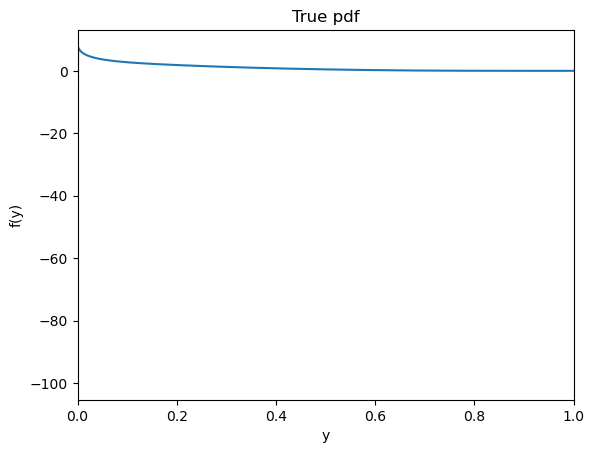

In [80]:
# plot
pt = np.linspace(x_min, x_max, 1000)
plt.plot(pt, f(pt))
plt.xlim(0, 1)
plt.xlabel("y")
plt.ylabel("f(y)")
plt.title("True pdf")
plt.show()

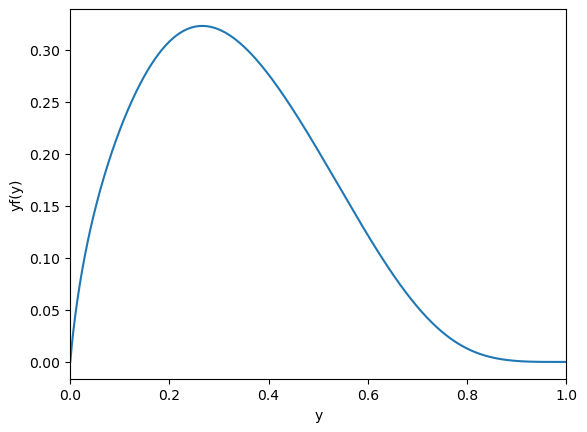

In [53]:
# plot
pt = np.linspace(x_min, x_max, 1000)
plt.plot(pt, pt*f(pt))
plt.xlim(0, 1)
plt.xlabel("y")
plt.ylabel("yf(y)")
plt.show()

## Data Generation

In [78]:
# Create a grid of (x, Q2) points
Q2_grid = [30, 50, 80, 100, 120, 150]
x_grid = np.linspace(0.01, 0.99, 50)

xQ2 = np.array([(x, Q2) for Q2 in Q2_grid for x in x_grid], dtype=float)

In [ ]:
# load HERA xF3 data
with open("structure_function_F3/HERA_xF3.json") as file:
    hera_data = json.load(file)

data = {"x": [], "Q2": [], "xF3_exp": [], "error_exp": []}
for dat in hera_data["values"]:
    Q2 = dat["x"][0]["value"]
    x = dat["x"][1]["value"]
    xF3 = dat["y"][0]["value"]
    error = 0
    for error_type in dat["y"][0]["errors"]:
        error += float(error_type["symerror"]) ** 2
    error = error ** 0.5
    data["error_exp"].append(error)
    data["Q2"].append(float(Q2))
    data["x"].append(float(x))
    data["xF3_exp"].append(float(xF3))
data = pd.DataFrame(data)

xQ2 = data[["x", "Q2"]].values

In [23]:
# load HERA kinematics for EM-SIGMARED
with open("HERA_NC_318GEV/kinematics_EM-SIGMARED.yaml") as file:
    data = yaml.safe_load(file)

xQ2 = np.empty((0, 2), dtype=float)
for i in range(len(data["bins"])):
    x = data["bins"][i]["x"]["mid"]
    Q2 = data["bins"][i]["Q2"]["mid"]
    xQ2 = np.append(xQ2, [[x, Q2]], axis=0)

In [89]:
# load data from output of data_T3.py
data = np.load("Dataset/data_208.npz")

# Access individual arrays
Q0        = data["Q0"]
q2_vals   = data["q2_vals"]
y_vals    = data["y_vals"]
grid      = data["grid"]
xt3_grid  = data["xt3_grid"]
t3_grid   = data["t3_grid"]
T_theory  = data["T_theory"]
xT_theory = data["xT_theory"]
D         = data["D"]
W         = data["W"]
Sigma      = data["Sigma"]
xQ2 = data["kinematics"]

In [25]:
# initialize an empty covariance matrix
Sigma = np.zeros((len(xQ2), len(xQ2)))

# compute the covariance matrix based on eq (2.3) of https://arxiv.org/pdf/2501.08818
with open("HERA_NC_318GEV/uncertainties_EM-SIGMARED.yaml") as file:
    uncertainties = yaml.safe_load(file)['bins']
for i in range(len(xQ2)):
    for j in range(len(xQ2)):
        if i == j:
            Sigma[i, i] = uncertainties[i]['stat']
        else:
            for sys_cor, value in uncertainties[i].items():
                if sys_cor != 'stat':
                    Sigma[i, j] += value * uncertainties[j][sys_cor]

### Compute theory predictions

In [110]:
# True c parameter
c = 1e5

In [111]:
# Standard Model prediction
"""
T = T_sm(xQ2=xQ2, f=f, 
    sigma_NLO=lambda x, Q2: sigma_T3_NLO(x, Q2, alpha_s=pdf.alphasQ2, gV=0.5),
    gV=0.5,
    n_quad=1000
)
"""
T = T_sm_FK(f=f, W=W, grid=grid)

# True prediction given c
mu = gaussian_mean(c=c, T=T, xQ2=xQ2, klin=klin, kquad=kquad)

In [105]:
sum(abs(T-T_theory) > 1e-5)

np.int64(0)

### Generate pseudo-data

In [67]:
# Generate Gaussian data with mean = gaussian_mean and diagonal covariance
variance = 1e-5
D = mu + np.sqrt(variance) * np.random.randn(len(mu))
Sigma = np.eye(len(mu)) * variance

In [112]:
# Generate data with the full covariance
rng = np.random.default_rng(seed=42)
D = rng.multivariate_normal(mean=mu, cov=Sigma)

In [107]:
min(np.linalg.eigvals(Sigma))

np.float64(3.640327688817945e-07)

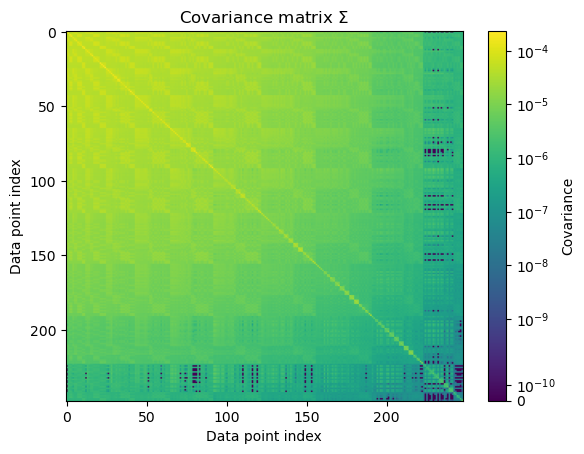

In [113]:
# Visualize the covariance matrix
import matplotlib.colors as mcolors



# --- covariance matrix (symmetric log scale) ---
vmax = Sigma.max()
vmin_pos = Sigma[Sigma > 0].min() if (Sigma > 0).any() else 1e-10
norm = mcolors.SymLogNorm(linthresh=vmin_pos, vmin=0, vmax=vmax)
im0 = plt.imshow(Sigma, aspect='auto', cmap='viridis', norm=norm)
plt.colorbar(im0, label='Covariance')
plt.title('Covariance matrix $\\Sigma$')
plt.xlabel('Data point index')
plt.ylabel('Data point index')


plt.show()

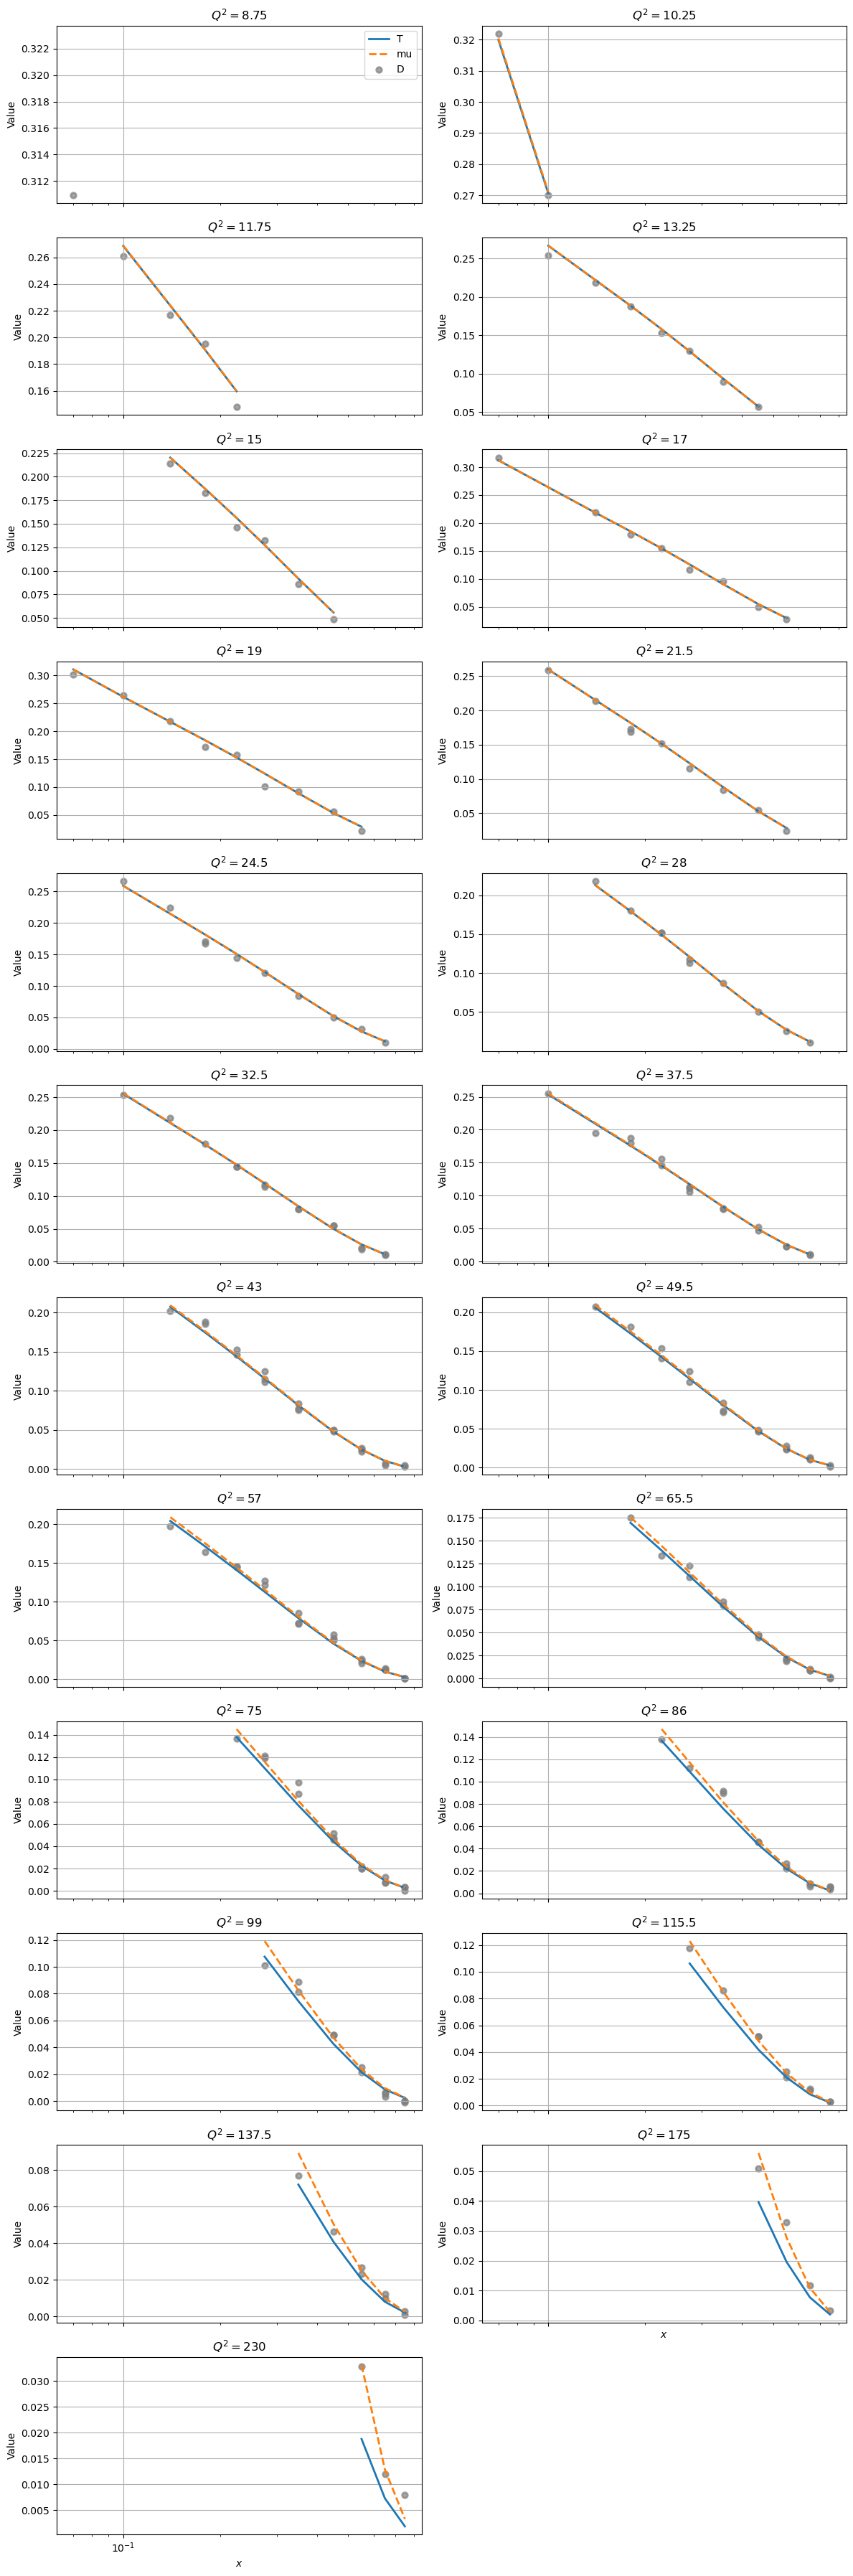

In [114]:
plot_by_Q2({"T": T, "mu": mu, "D": D}, xQ2=xQ2, ncols=2, x_log_scale=True, series_styles={
    "T": dict(linestyle="-", linewidth=2, color="C0"),
    "mu": dict(linestyle="--", linewidth=2, color="C1"),
    "D": dict(kind="scatter", color="gray", s=30, alpha=0.7)
})

## Estimation

In [71]:
# Specify spline basis for fitting

# Degree of B-splines
degree = 3
# Number of basis
M = 10

B = bspline_basis(degree, M, x_min, x_max)

w_norm = np.array([Bk.integrate(x_min, x_max) for Bk in B])

#A = build_f_design_matrix(xQ2=xQ2, B=B, sigma_NLO=lambda x, Q2: sigma_T3_NLO(x, Q2, alpha_s=pdf.alphasQ2, gV=0.5), 
#                              gV=0.5, n_quad=2000)
A = build_f_design_matrix_FK(B=B, W=W, grid=grid)

In [30]:
beta_hat, history = mle_beta(D=D, A=A, c=0, v=v_c, xQ2=xQ2, Sigma=Sigma, w_norm=w_norm, beta0=None, nonneg_beta=True, beta_opt="SLSQP", return_history=True)
c_hat = mle_c(D=D, A=A, v=v_c, beta=beta_hat, xQ2=xQ2, Sigma=Sigma, c_opt="scipy_optimize")

In [ ]:
beta_hat, c_hat = mle_beta_c_ca(D=D, A=A, v=v_c, xQ2=xQ2, Sigma=Sigma, w_norm=w_norm, c0=0.0, beta0=None, 
                beta_opt="SLSQP", c_opt="scipy_optimize", nonneg_beta=True, max_iter=20, eps=10)

Initialization: c=0.0, ||beta||_2=5.171989894954593
Iter 1: c=437187.7626, ||beta||_2=5.172, c_change=437187.7626, beta_change=0.0003
Final: c=437187.7626, ||beta||_2=5.172 after 2 iters


In [72]:
# fit beta and c
res, history = fit_beta_c(D=D, A=A, v=v_c, v_prime=v_prime_c, w_norm=w_norm, xQ2=xQ2, Sigma=Sigma, nonneg_beta=True,
                 return_history=True, opt_method="SLSQP")
beta_hat = res['beta_hat']
c_hat = res['c_hat']

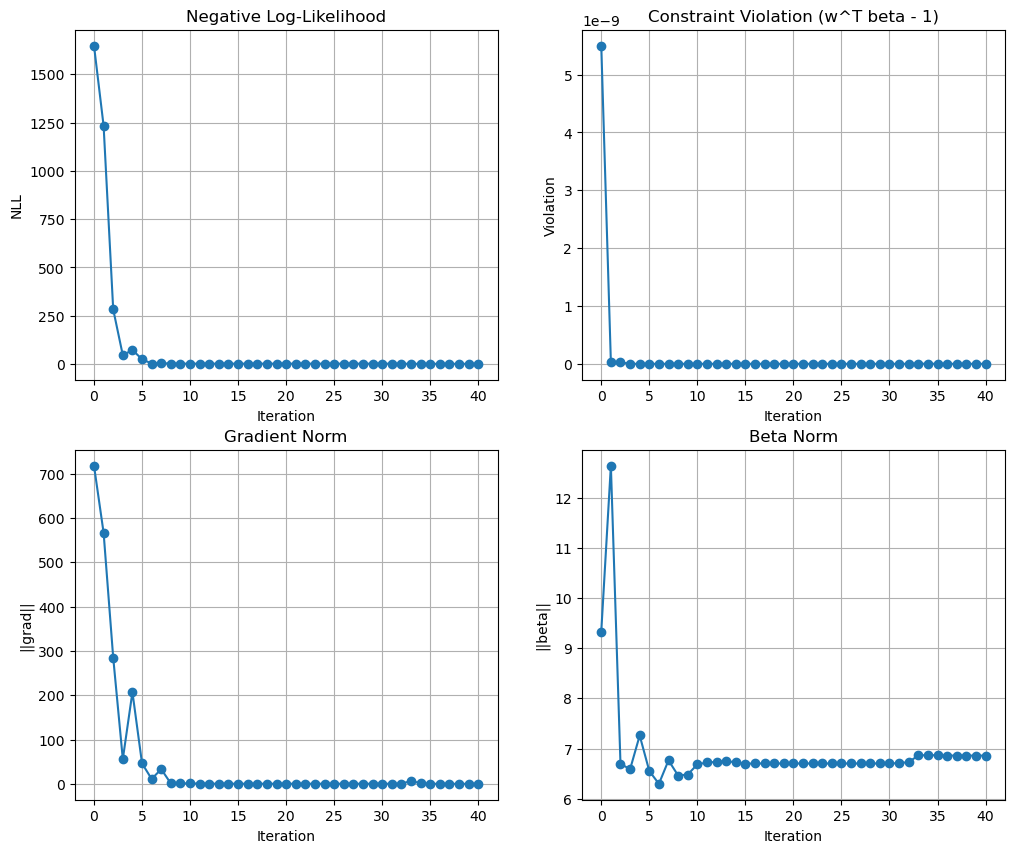

In [73]:
# Plot convergence history
history_df = pd.DataFrame(history)
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes[0, 0].plot(history_df['loss'], marker='o')
axes[0, 0].set_title("Negative Log-Likelihood")
axes[0, 0].set_xlabel("Iteration")
axes[0, 0].set_ylabel("NLL")
axes[0, 0].grid()

axes[0, 1].plot(history_df['constr_viol'], marker='o')
axes[0, 1].set_title("Constraint Violation (w^T beta - 1)")
axes[0, 1].set_xlabel("Iteration")
axes[0, 1].set_ylabel("Violation")
axes[0, 1].grid()

axes[1, 0].plot(history_df['grad_norm'], marker='o')
axes[1, 0].set_title("Gradient Norm")
axes[1, 0].set_xlabel("Iteration")
axes[1, 0].set_ylabel("||grad||")
axes[1, 0].grid()

axes[1, 1].plot(history_df['beta_norm'], marker='o')
axes[1, 1].set_title("Beta Norm")
axes[1, 1].set_xlabel("Iteration")
axes[1, 1].set_ylabel("||beta||")
axes[1, 1].grid()

In [32]:
nll, grad = make_nll_and_grad(D, A, v_c, v_prime_c, xQ2=xQ2, Sigma=Sigma)

In [33]:
nll(np.append(beta_hat, c_hat))

np.float64(129590790.97907524)

In [74]:
results_df = pd.DataFrame({
    "Parameter": [f"beta_{m}" for m in range
    (M)] + ["c"],
    "Fitted": np.round(np.concatenate([beta_hat, np.array([c_hat])]), 4),
})
print(results_df)
print("True c:", c)
print("Normalization constraint:", np.sum(beta_hat * w_norm))  # should be 1.0

   Parameter      Fitted
0     beta_0      5.3897
1     beta_1      3.2432
2     beta_2      2.1993
3     beta_3      1.2801
4     beta_4      0.6705
5     beta_5      0.2246
6     beta_6      0.0192
7     beta_7      0.0115
8     beta_8      0.0000
9     beta_9      0.7140
10         c  97184.1897
True c: 100000.0
Normalization constraint: 0.9999999999999999


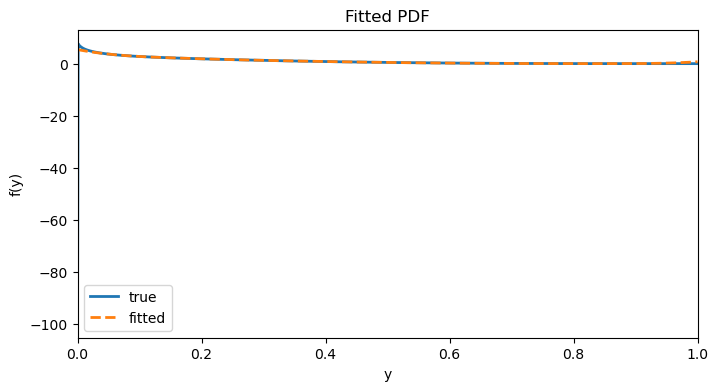

In [81]:
y_eval = np.linspace(x_min, x_max, 1000)

fy_fit = np.zeros_like(y_eval, dtype=float)
for betak, Bk in zip(beta_hat, B):
    fy_fit += betak * Bk(y_eval)


# Plot the resulting function
plt.figure(figsize=(8,4))
plt.plot(y_eval, f(y_eval), lw=2, label="true")
plt.plot(y_eval, fy_fit, lw=2, label="fitted", ls='--')
plt.title("Fitted PDF")
plt.xlabel("y")
plt.ylabel("f(y)")
plt.xlim((0,1))
plt.legend()

In [82]:
mu_hat = gaussian_mean_basis(c_hat, beta_hat, A, xQ2=xQ2, klin=klin, kquad=kquad)

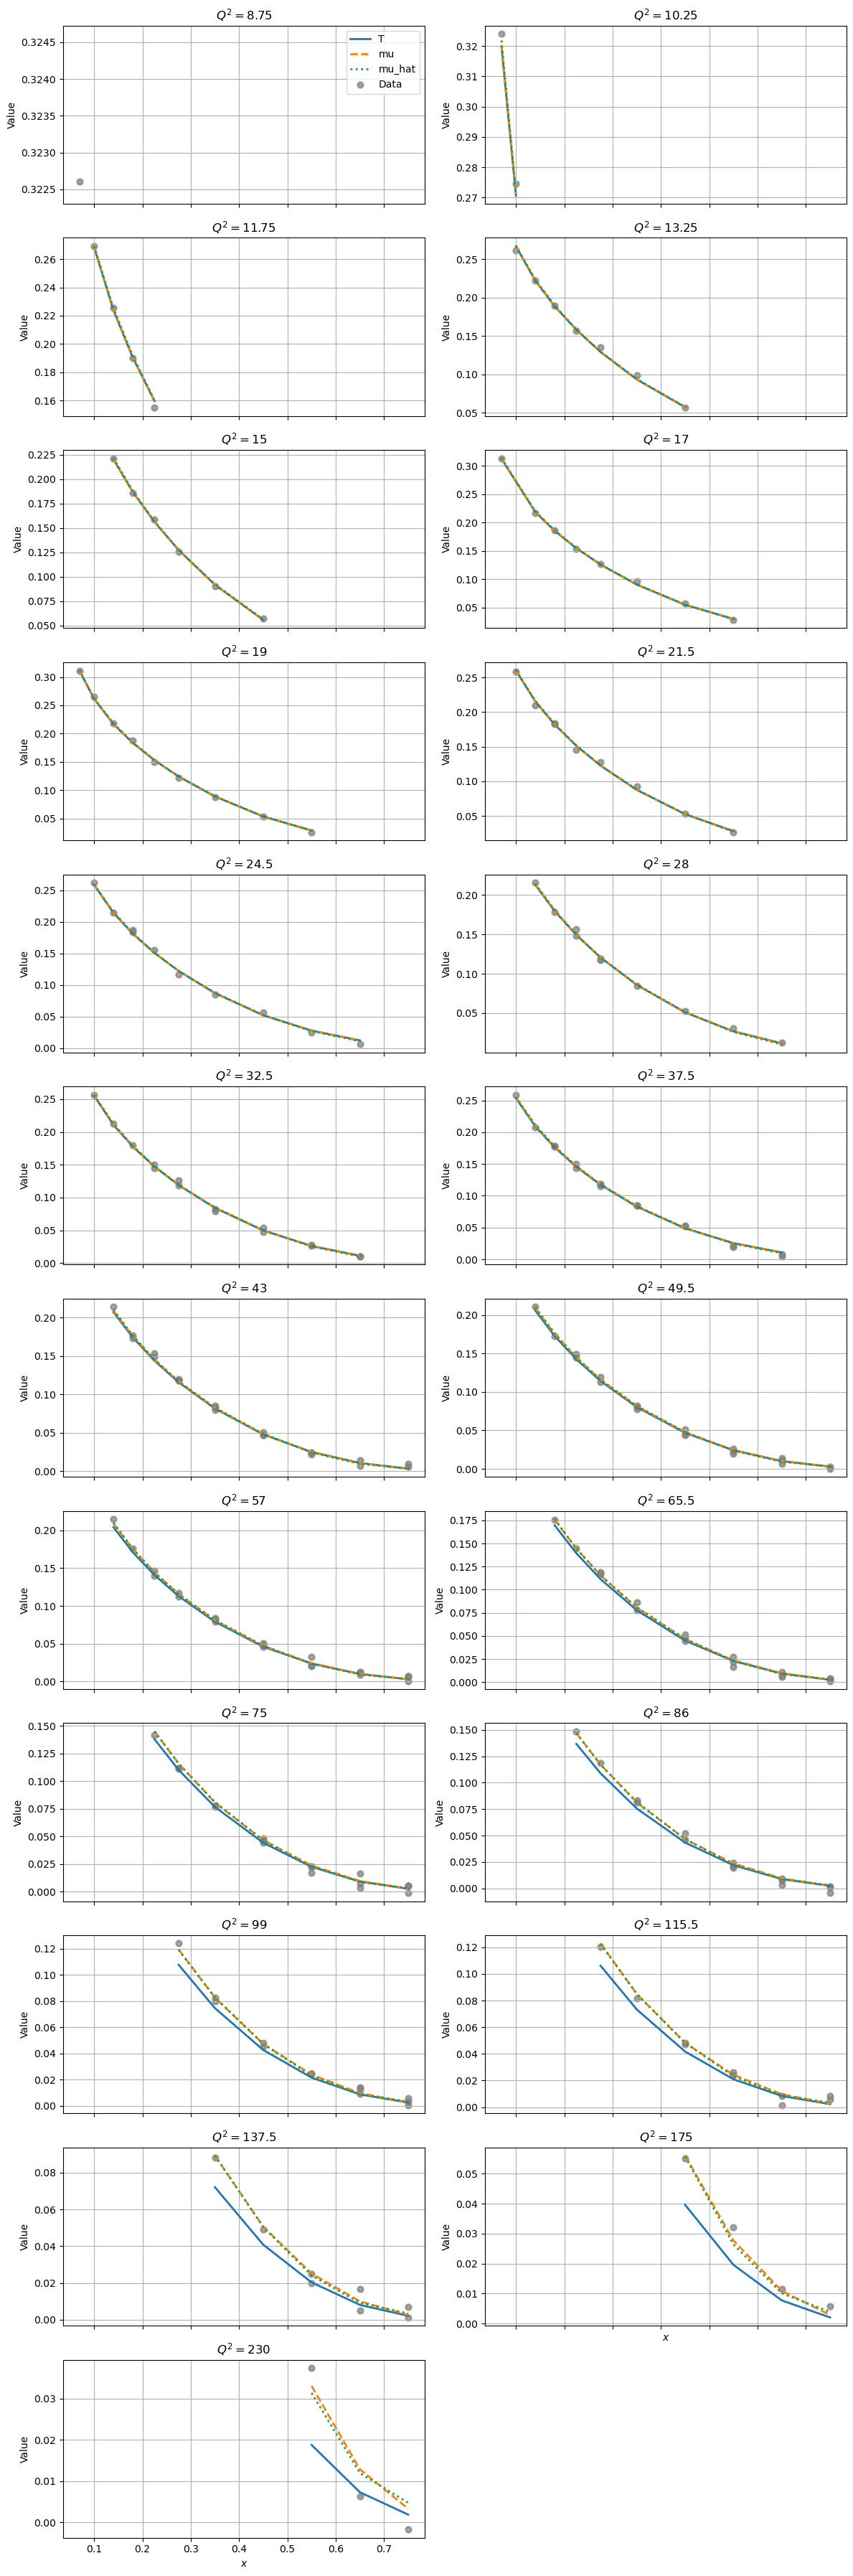

In [83]:
plot_by_Q2({"T": T, "mu": mu, "mu_hat": mu_hat, "Data": D}, xQ2=xQ2, series_styles={
    "T": dict(linestyle="-", linewidth=2, color="C0"),
    "mu": dict(linestyle="--", linewidth=2, color="C1"),
    "mu_hat": dict(linestyle=":", linewidth=2, color="C2"),
    "Data": dict(kind="scatter", color="gray", s=30, alpha=0.7)
})

## Compute One-Step Estimator

In [84]:
K = build_K_matrix(c_hat, A, xQ2=xQ2, klin=klin, kquad=kquad)
K_prime = build_K_prime_matrix(c_hat, A, xQ2=xQ2, klin=klin, kquad=kquad)

In [85]:
#c_one_step, info = one_step_c(D, K, K_prime, beta_hat, c_hat, w_norm, s2_diag=np.full(len(D), variance))
c_one_step, info = one_step_c(D, K, K_prime, beta_hat, c_hat, w_norm, Sigma=Sigma)

In [86]:
# print results
print("plug-in c estimate:", c_hat)
print("One-step c estimate:", c_one_step)
print("EIF:", info['eif'])

plug-in c estimate: 97184.18973277725
One-step c estimate: 99072.00553016046
EIF: 1887.8157973832167


## Experiment

In [102]:
def setup_experiment(pdf, c, f, xQ2, gV, alpha_s, degree, M, data_var=None, data_Sigma=None, opt="joint",
                    c_opt="scipy_optimize", beta_opt="SLSQP", Lambda=Lambda, c0=0.0, beta0=None, 
                    x_min=x_min, x_max=x_max, Q2_min=Q2_min, Q2_max=Q2_max, klin=klin, kquad=kquad, 
                    sigma_NLO=sigma_T3_NLO, nonneg_beta=True, ncol_plots=4, x_log_scale=True,
                    parametrize="f", return_history=False):
    """
    One-time setup for experiment: compute basis, smearing matrix, and true mean.
    These quantities don't change across simulations.

    Parameters
    ----------
    pdf: str
        PDF set name.
    c : float
        True c.
    f : callable
        True PDF f(y).
    xQ2 : (N,2) array
        Grid points for x and Q^2.
    gV : float
        Value of gV.
    alpha_s : float
        Value of alpha_s.
    data_var : float
        Variance of the data noise.
    data_Sigma : (N, N) array
        Covariance matrix of the data noise.
    degree : int
        Degree of B-spline basis.
    M : int
        Number of basis functions.
    opt : str, optional
        Optimization method ("joint", "separate", or "ca").
    c_opt : str, optional
        Optimization method for c ("scipy_optimize" or "grid_search").
    beta_opt : str, optional
        Optimization method for beta ("SLSQP", "trust-constr", or "closed_form").
    c0: float, optional
        Initial guess for c when using separate optimization or coordinate ascent.
    beta0: (M,) array, optional
        Initial guess for beta when using coordinate ascent.
    Lambda : float, optional
        Suppresing factor.
    x_min : float, optional
        Minimum x value for the basis.
    x_max : float, optional
        Maximum x value for the basis.
    Q2_min : float, optional
        Minimum Q^2.
    Q2_max : float, optional
        Maximum Q^2.
    klin : callable, optional
        First order polynomial coefficient.
    kquad : callable, optional
        Second order polynomial coefficient.
    sigma_NLO: 
        callable sigma_NLO(z, Q2) that can be vectorized in z
    nonneg_beta : bool, optional
        If True, enforce non-negativity constraint on beta.
    ncol_plots : int, optional
        Number of columns for plots.
    x_log_scale : bool, optional
        If True, use logarithmic scale for x-axis in plots.
    parametrize : str, optional
        PDF parametrization: "f" fits f(y) directly (basis expands f),
        "yf" fits yf(y) (basis expands y*f(y), so f(y) = basis/y).
    return_history : bool, optional
        If True, return optimization history for diagnostics.

    Returns
    -------
    dict
        Setup information including B, A, w_norm, T, mu, and other parameters.
    """
    if parametrize not in ("f", "yf"):
        raise ValueError(f"parametrize must be 'f' or 'yf', got {parametrize!r}")
    if data_var is None and data_Sigma is None:
        raise ValueError("Must specify either data_var or data_Sigma.")

    # define local klin and kquad that uses the provided Lambda, Q2_min, Q2_max
    klin_local = lambda x: klin(x, Lambda=Lambda, Q2_min=Q2_min, Q2_max=Q2_max)
    kquad_local = lambda x: kquad(x, Lambda=Lambda, Q2_min=Q2_min, Q2_max=Q2_max)

    # --- Smeared PDF T and mean mu (true values) ---
    T = T_sm(
        xQ2, f,
        sigma_NLO=lambda x, Q2: sigma_NLO(x, Q2, alpha_s=alpha_s, gV=gV),
        gV=gV,
        n_quad=2000
    )

    mu = gaussian_mean(c=c, T=T, xQ2=xQ2, klin=klin_local, kquad=kquad_local)

    # --- Basis and smearing matrix ---
    B = bspline_basis(degree, M, x_min, x_max)

    if parametrize == "f":
        w_norm = np.array([Bk.integrate(x_min, x_max) for Bk in B])
        A = build_f_design_matrix(xQ2, B, sigma_NLO=lambda x, Q2: sigma_NLO(x, Q2, alpha_s=alpha_s, gV=gV),
                                  gV=gV, n_quad=2000)
    else:  # "yf"
        w_norm = np.array([quad(lambda y, Bk=Bk: Bk(y) / y, x_min, x_max)[0] for Bk in B])
        A = build_yf_design_matrix(xQ2, B, sigma_NLO=lambda x, Q2: sigma_NLO(x, Q2, alpha_s=alpha_s, gV=gV),
                                   gV=gV, n_quad=2000)

    return {
        'PDF': pdf,
        'B': B,
        'A': A,
        'w_norm': w_norm,
        'T': T,
        'mu': mu,
        'c': c,
        'f': f,
        'xQ2': xQ2,
        'gV': gV,
        'Lambda': Lambda,
        'alpha_s': alpha_s,
        'M': M,
        'degree': degree,
        'data_var': data_var,
        'data_Sigma': data_Sigma,
        'x_min': x_min,
        'x_max': x_max,
        'Q2_min': Q2_min,
        'Q2_max': Q2_max,
        'klin': klin_local,
        'kquad': kquad_local,
        'opt': opt,
        'c_opt': c_opt,
        'beta_opt': beta_opt,
        'c0': c0,
        'beta0': beta0,
        'nonneg_beta': nonneg_beta,
        'ncol_plots': ncol_plots,
        'x_log_scale': x_log_scale,
        'parametrize': parametrize,
        'return_history': return_history
    }


def run_single_experiment(setup_dict, diagnostics=False):
    """
    Run a single experiment with precomputed setup.
    Only generates new data and runs estimation.

    Parameters
    ----------
    setup_dict : dict
        Dictionary returned by setup_experiment().
    diagnostics : bool, optional
        If True, print diagnostic information and plots.

    Returns
    -------
    c_hat : float
        MLE estimate of c.
    c_one_step : float
        One-step corrected estimate of c.
    info : dict (only if diagnostics=True)
        Additional diagnostic information.
    """
    # Extract precomputed quantities
    A = setup_dict['A']
    B = setup_dict['B']
    w_norm = setup_dict['w_norm']
    mu = setup_dict['mu']
    T = setup_dict['T']
    c = setup_dict['c']
    f = setup_dict['f']
    xQ2 = setup_dict['xQ2']
    M = setup_dict['M']
    data_var = setup_dict['data_var']
    data_Sigma = setup_dict['data_Sigma']
    x_min = setup_dict['x_min']
    x_max = setup_dict['x_max']
    klin = setup_dict['klin']
    kquad = setup_dict['kquad']
    _v_c = lambda c, xQ2: v_c(c, xQ2, klin=klin, kquad=kquad)
    _v_prime_c = lambda c, xQ2: v_prime_c(c, xQ2, klin=klin, kquad=kquad)
    opt = setup_dict['opt']
    c_opt = setup_dict['c_opt']
    beta_opt = setup_dict['beta_opt']
    c0 = setup_dict['c0']
    beta0 = setup_dict['beta0']
    nonneg_beta = setup_dict['nonneg_beta']
    ncol_plots = setup_dict['ncol_plots']
    x_log_scale = setup_dict['x_log_scale']
    parametrize = setup_dict['parametrize']
    return_history = setup_dict['return_history']

    # =========================
    # Generate new data
    # =========================
    if data_Sigma is not None:
        rng = np.random.default_rng(seed=None)  # use a different seed for each run
        D = rng.multivariate_normal(mean=mu, cov=data_Sigma)
    else:
        D = mu + np.sqrt(data_var) * np.random.randn(len(mu))
        data_Sigma = np.eye(len(mu)) * data_var

    # =========================
    # MLE fitting
    # =========================
    if opt == "joint":
        if return_history:
            res, history = fit_beta_c(D, A, _v_c, _v_prime_c, w_norm, xQ2, Sigma=data_Sigma, nonneg_beta=nonneg_beta, opt_method=beta_opt, return_history=True)
        else:
            res = fit_beta_c(D, A, _v_c, _v_prime_c, w_norm, xQ2, Sigma=data_Sigma, nonneg_beta=nonneg_beta, opt_method=beta_opt, return_history=False)
        beta_hat = res['beta_hat']
        c_hat = res['c_hat']
    elif opt == "separate":
        if return_history:
            beta_hat, history = mle_beta(D=D, A=A, c=c0, v=_v_c, xQ2=xQ2, Sigma=data_Sigma, w_norm=w_norm, beta0=None, nonneg_beta=nonneg_beta, beta_opt=beta_opt, return_history=True)
        else:
            beta_hat = mle_beta(D=D, A=A, c=c0, v=_v_c, xQ2=xQ2, Sigma=data_Sigma, w_norm=w_norm, beta0=None, nonneg_beta=nonneg_beta, beta_opt=beta_opt, return_history=False)
        c_hat = mle_c(D=D, A=A, v=_v_c, beta=beta_hat, xQ2=xQ2, Sigma=data_Sigma, c_opt=c_opt)
        res = {'beta_hat': beta_hat, 'c_hat': c_hat}
    else:  # opt == "ca"
        beta_hat, c_hat = mle_beta_c_ca(D=D, A=A, v=_v_c, xQ2=xQ2, Sigma=data_Sigma, w_norm=w_norm, 
                                        c0=c0, beta0=beta0, beta_opt=beta_opt, c_opt=c_opt, nonneg_beta=nonneg_beta, max_iter=20, eps=10)
        res = {'beta_hat': beta_hat, 'c_hat': c_hat}        
    
    mu_hat = gaussian_mean_basis(c_hat, beta_hat, A, xQ2, klin=klin, kquad=kquad)

    # =========================
    # One-step update
    # =========================
    K = build_K_matrix(c_hat, A, xQ2, klin=klin, kquad=kquad)
    K_prime = build_K_prime_matrix(c_hat, A, xQ2, klin=klin, kquad=kquad)
    if data_Sigma is not None:
        c_one_step, one_step_info = one_step_c(D, K, K_prime, beta_hat, c_hat, w_norm, Sigma=data_Sigma)
    else:
        c_one_step, one_step_info = one_step_c(D, K, K_prime, beta_hat, c_hat, w_norm, s2_diag=np.full(len(D), data_var))
    mu_one_step = gaussian_mean_basis(c_one_step, beta_hat, A, xQ2, klin=klin, kquad=kquad)

    # =========================
    # Diagnostics (visual)
    # =========================
    if diagnostics:
        info = {}
  
        # ---- (1) PDF fit ----
        y_eval = np.linspace(x_min, x_max, 5000)
        basis_fit = sum(b * Bk(y_eval) for b, Bk in zip(beta_hat, B))

        if parametrize == "f":
            fy_fit = basis_fit           # basis expands f directly
        else:  # "yf"
            fy_fit = basis_fit / y_eval  # basis expands yf, so f = basis/y

        fig, axes = plt.subplots(1, 2, figsize=(12, 4))

        #  f(y) 
        axes[0].plot(y_eval, f(y_eval), lw=2.5, label="True $f(y)$")
        axes[0].plot(y_eval, fy_fit, lw=2.5, ls="--", label="Fitted $\\hat f(y)$")
        axes[0].set_title("PDF fit")
        axes[0].set_xlabel("y")
        axes[0].set_ylabel("f(y)")
        axes[0].grid(True, color="0.85", linewidth=1.0)
        axes[0].legend()

        #  y f(y) 
        axes[1].plot(y_eval, y_eval * f(y_eval), lw=2.5, label="True $y f(y)$")
        axes[1].plot(y_eval, y_eval * fy_fit, lw=2.5, ls="--", label="Fitted $y \\hat f(y)$")
        axes[1].set_title("PDF fit")
        axes[1].set_xlabel("y")
        axes[1].set_ylabel("$y f(y)$")
        axes[1].grid(True, color="0.85", linewidth=1.0)
        axes[1].legend()

        plt.tight_layout()
        plt.show()

        # ---- (2) Mean fit by Q^2 ----
        plot_by_Q2({"T": T, "mu": mu, "mu_hat": mu_hat, "mu_one_step": mu_one_step, "Data": D}, xQ2=xQ2, ncols=ncol_plots, x_log_scale=x_log_scale, series_styles={
            "T": dict(linestyle="-", linewidth=3, color="C0"),
            "mu": dict(linestyle="--", linewidth=3, color="C1"),
            "mu_hat": dict(linestyle=":", linewidth=3, color="C2"),
            "mu_one_step": dict(linestyle="-.", linewidth=3, color="C3"),
            "Data": dict(kind="scatter", color="gray", s=30, alpha=0.7)
        })
                
        # ---- (3) Convergence history ----
        if return_history:
            # Plot convergence history
            history_df = pd.DataFrame(history)
            fig, axes = plt.subplots(2, 2, figsize=(12, 10))
            axes[0, 0].plot(history_df['loss'], marker='o')
            axes[0, 0].set_title("Negative Log-Likelihood")
            axes[0, 0].set_xlabel("Iteration")
            axes[0, 0].set_ylabel("NLL")
            axes[0, 0].grid()

            axes[0, 1].plot(history_df['constr_viol'], marker='o')
            axes[0, 1].set_title("Constraint Violation (w^T beta - 1)")
            axes[0, 1].set_xlabel("Iteration")
            axes[0, 1].set_ylabel("Violation")
            axes[0, 1].grid()

            axes[1, 0].plot(history_df['grad_norm'], marker='o')
            axes[1, 0].set_title("Gradient Norm")
            axes[1, 0].set_xlabel("Iteration")
            axes[1, 0].set_ylabel("||grad||")
            axes[1, 0].grid()

            axes[1, 1].plot(history_df['beta_norm'], marker='o')
            axes[1, 1].set_title("Beta Norm")
            axes[1, 1].set_xlabel("Iteration")
            axes[1, 1].set_ylabel("||beta||")
            axes[1, 1].grid()

        # ---- Numerical table ----
        results_df = pd.DataFrame({
            "Parameter": ["c_hat", "c_one_step", "True c"] + [f"beta_{m}" for m in range(M)],
            "Value": np.concatenate([[c_hat, c_one_step, c], beta_hat])
        })
        print(results_df.round(6))

        # check normalization constraint
        print("Normalization constraint (w^T beta_hat):", float(w_norm @ beta_hat))
        # check fitted pdf is a valid density
        fy_integral = fixed_quad(lambda y: sum(b * Bk(y) for b, Bk in zip(beta_hat, B)) / (y if parametrize == "yf" else 1.0),
                                 x_min, x_max, n=1000)[0]
        print(f"Fitted pdf integrates to ({parametrize} parametrize):", fy_integral)

        info['mle'] = res
        info['one_step'] = one_step_info
        return c_hat, c_one_step, info
    else:
        return c_hat, c_one_step


def experiment(c, f, xQ2, gV, alpha_s, degree, M, data_var=None, data_Sigma=None, opt="joint", 
               c_opt="scipy_optimize", beta_opt="SLSQP", c0=0.0, beta0=None,
               Lambda=Lambda, x_min=x_min, x_max=x_max, Q2_min=Q2_min, Q2_max=Q2_max, klin=klin, kquad=kquad, 
               sigma_NLO=sigma_T3_NLO, nonneg_beta=True, diagnostics=False, ncol_plots=4, x_log_scale=True,
               parametrize="f", return_history=False):
    """
    Run a full experiment with data generation, MLE fitting, and one-step update.

    This is a convenience wrapper that calls setup_experiment() and run_single_experiment().
    For simulations, use setup_experiment() once, then call run_single_experiment() repeatedly.

    Parameters
    ----------
    c : float
        True c.
    f : callable
        True PDF f(y).
    xQ2 : (n_xQ2,) array
        Grid points for x and Q^2.
    gV : float
        coupling constant gV.
    alpha_s : float
        alpha_s function or value.
    data_var : float
        Variance of the data noise.
    data_Sigma : (N, N) array
        Covariance matrix of the data noise. If specified, overrides data_var.
    degree : int
        Degree of B-spline basis.
    M : int
        Number of basis functions.
    opt : str, optional
        Optimization method ("joint", "separate", or "ca").
    c_opt : str, optional
        Optimization method for c ("scipy_optimize" or "grid_search").
    beta_opt : str, optional
        Optimization method for beta ("SLSQP" or "closed_form").
    c0: float, optional
        Initial guess for c when using separate optimization or coordinate ascent.
    beta0: (M,) array, optional
        Initial guess for beta when using coordinate ascent.
    Lambda : float, optional
        Suppresing factor.
    x_min : float, optional
        Minimum x value for the basis.
    x_max : float, optional
        Maximum x value for the basis.
    Q2_min : float, optional
        Minimum Q^2.
    Q2_max : float, optional
        Maximum Q^2.
    klin : callable, optional
        first order of polynomial coefficient.
    kquad : callable, optional
        second order of polynomial coefficient.
    sigma_NLO : callable, optional
        NLO part of the smearing kernel
    nonneg_beta : bool, optional
        If True, enforce non-negativity constraint on beta.
    diagnostics : bool, optional
        If True, print diagnostic information.
    ncol_plots : int, optional
        Number of columns for plots.
    x_log_scale : bool, optional
        If True, use logarithmic scale for x-axis in plots.
    parametrize : str, optional
        PDF parametrization: "f" fits f(y) directly, "yf" fits y*f(y).
    return_history : bool, optional
        If True, return optimization history for diagnostics.

    Returns
    -------
    dict
        Results including fitted beta, c, one-step c, and diagnostics.
    """

    setup_dict = setup_experiment(c=c, f=f, xQ2=xQ2, gV=gV, alpha_s=alpha_s,
                                  data_var=data_var, data_Sigma=data_Sigma, degree=degree, M=M, opt=opt, 
                                  c_opt=c_opt, beta_opt=beta_opt, c0=c0, beta0=beta0,
                                  Lambda=Lambda, x_min=x_min, x_max=x_max, Q2_min=Q2_min, Q2_max=Q2_max,
                                  klin=klin, kquad=kquad, sigma_NLO=sigma_NLO,
                                  nonneg_beta=nonneg_beta, ncol_plots=ncol_plots, x_log_scale=x_log_scale,
                                  parametrize=parametrize, return_history=return_history)
    return run_single_experiment(setup_dict, diagnostics)


In [126]:
Q2_grid = [30, 50, 80, 100, 120, 150]
x_grid = np.linspace(0.01, 0.99, 50)

xQ2 = np.array([(x, Q2) for Q2 in Q2_grid for x in x_grid], dtype=float)

In [135]:
Q2_grid = [1000, 1200, 1500, 2000, 3000, 5000, 8000, 12000, 20000, 30000]
x_grid = np.linspace(0.1, 0.99, 20)
xQ2 = np.array([[x, Q2] for x in x_grid for Q2 in Q2_grid])

In [ ]:
# load HERA xF3 data
with open("structure_function_F3/HERA_xF3.json") as file:
    hera_data = json.load(file)

data = {"x": [], "Q2": [], "xF3_exp": [], "error_exp": []}
for dat in hera_data["values"]:
    Q2 = dat["x"][0]["value"]
    x = dat["x"][1]["value"]
    xF3 = dat["y"][0]["value"]
    error = 0
    for error_type in dat["y"][0]["errors"]:
        error += float(error_type["symerror"]) ** 2
    error = error ** 0.5
    data["error_exp"].append(error)
    data["Q2"].append(float(Q2))
    data["x"].append(float(x))
    data["xF3_exp"].append(float(xF3))
data = pd.DataFrame(data)

xQ2 = data[["x", "Q2"]].values

In [103]:
# load HERA kinematics for EM-SIGMARED
with open("HERA_NC_318GEV/kinematics_EM-SIGMARED.yaml") as file:
    data = yaml.safe_load(file)

xQ2 = np.empty((0, 2), dtype=float)
for i in range(len(data["bins"])):
    x = data["bins"][i]["x"]["mid"]
    Q2 = data["bins"][i]["Q2"]["mid"]
    xQ2 = np.append(xQ2, [[x, Q2]], axis=0)

# initialize an empty covariance matrix
Sigma = np.zeros((len(xQ2), len(xQ2)))

# compute the covariance matrix based on eq (2.3) of https://arxiv.org/pdf/2501.08818
with open("HERA_NC_318GEV/uncertainties_EM-SIGMARED.yaml") as file:
    uncertainties = yaml.safe_load(file)['bins']
for i in range(len(xQ2)):
    for j in range(len(xQ2)):
        if i == j:
            Sigma[i, i] = uncertainties[i]['stat']
        else:
            for sys_cor, value in uncertainties[i].items():
                if sys_cor != 'stat':
                    Sigma[i, j] += value * uncertainties[j][sys_cor]

In [ ]:
# Read the setup from the previous experiment
"""
pkl_path = "simulation_results/real-model-demo/run_7fa6ca2a.pkl"
with open(pkl_path, "rb") as pkl_file:
    data = pickle.load(pkl_file)

setup_dict = data["setup_dict"]
setup_dict['klin'] = lambda x: klin(x, Lambda=setup_dict['Lambda'], Q2_min=setup_dict['Q2_min'], Q2_max=setup_dict['Q2_max'])
setup_dict['kquad'] = lambda x: kquad(x, Lambda=setup_dict['Lambda'], Q2_min=setup_dict['Q2_min'], Q2_max=setup_dict['Q2_max'])
plug_in_estimates = data["plug_in_estimates"]
one_step_estimates = data["one_step_estimates"]
"""

In [136]:
setup_dict = setup_experiment(pdf=pdfset, c=1e5, f=f, xQ2=xQ2, gV=0.5, alpha_s=pdf.alphasQ2,
                                  data_var=0.0001, data_Sigma=None, degree=3, M=20, opt="separate", parametrize="f",
                                  c_opt="scipy_optimize", beta_opt="SLSQP", c0=0, beta0=None,
                                  Lambda=500, x_min=x_min, x_max=x_max, Q2_min=1000, Q2_max=30000,
                                  klin=klin, kquad=kquad, sigma_NLO=sigma_T3_NLO,
                                  nonneg_beta=True, ncol_plots=2, x_log_scale=False, return_history=True)

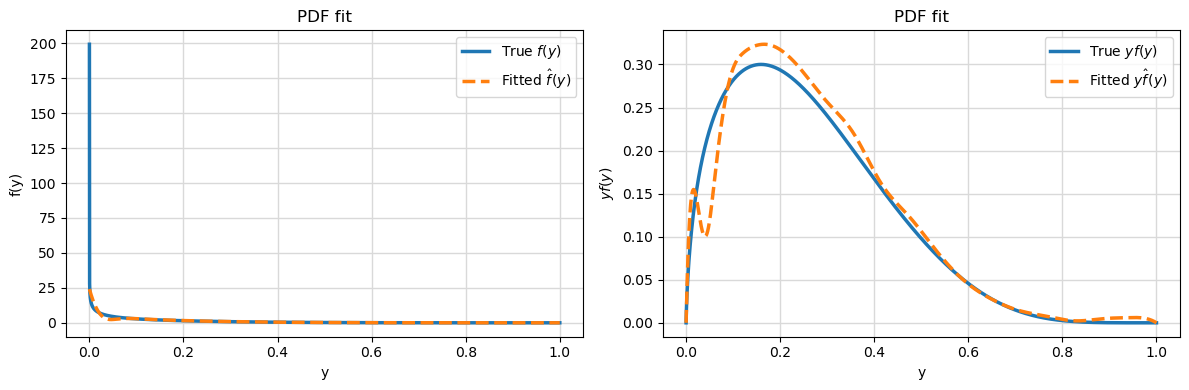

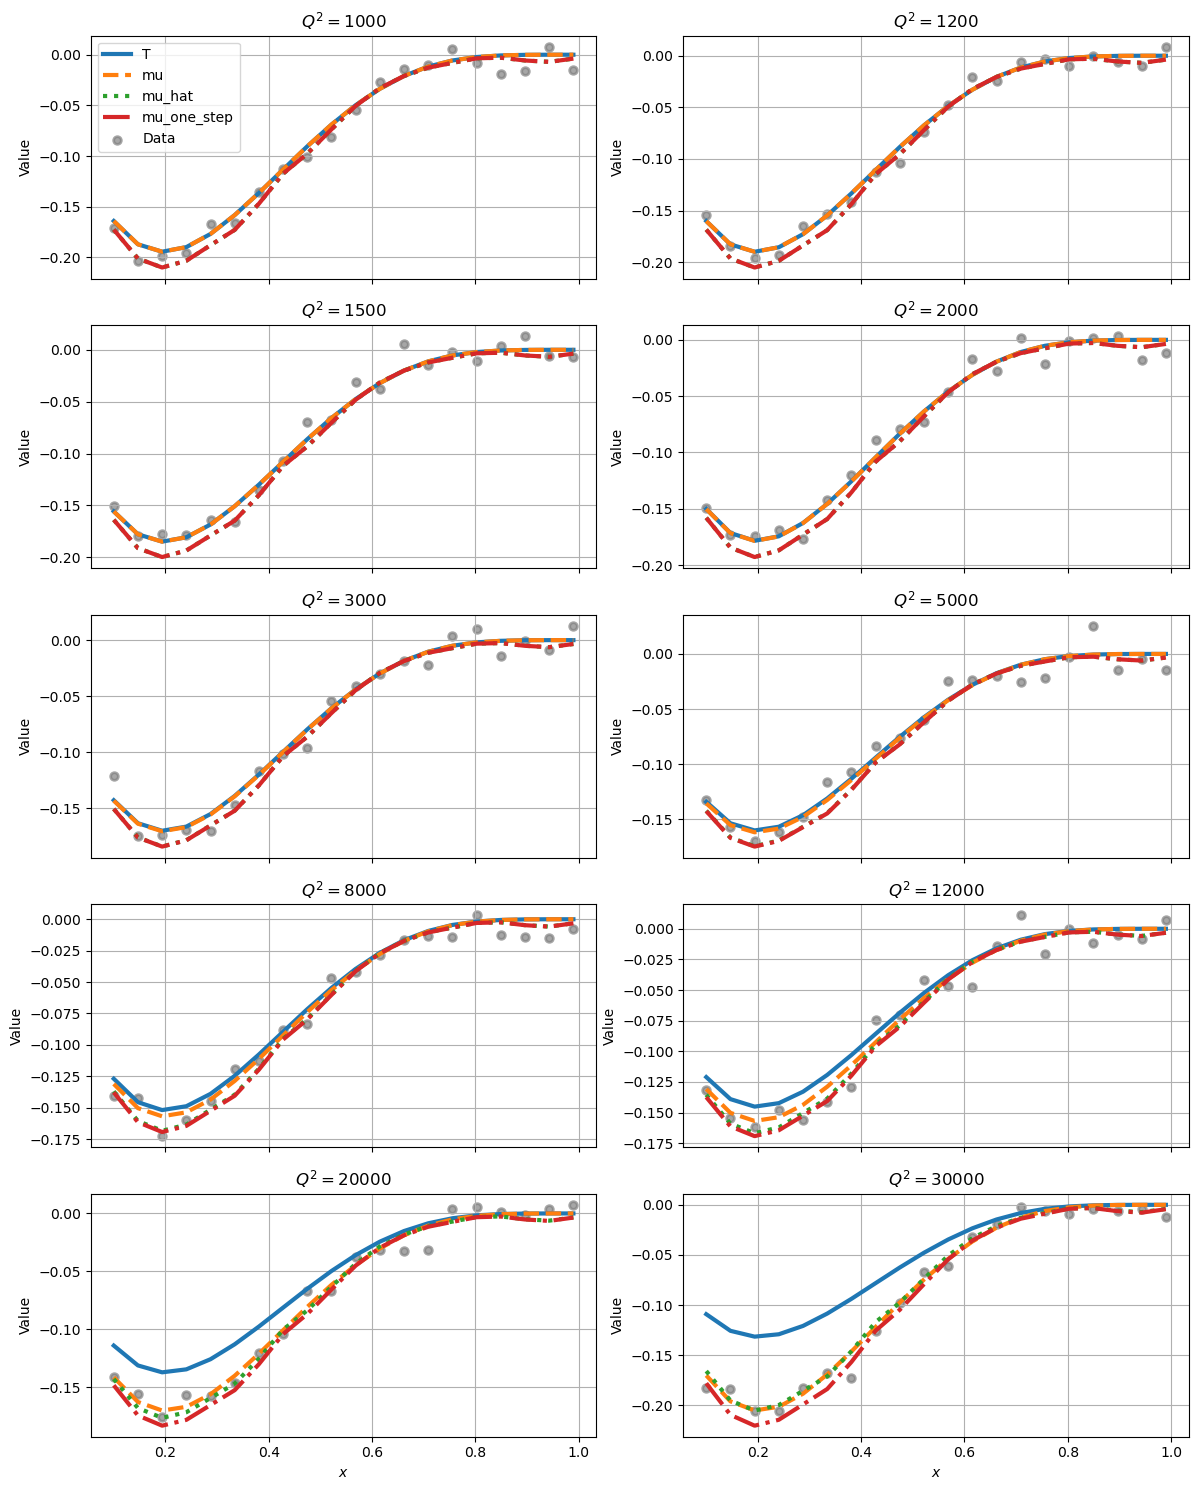

     Parameter          Value
0        c_hat   83413.128453
1   c_one_step   98739.113816
2       True c  100000.000000
3       beta_0      24.112567
4       beta_1       0.000000
5       beta_2       3.905265
6       beta_3       2.546041
7       beta_4       1.795606
8       beta_5       1.248908
9       beta_6       0.853697
10      beta_7       0.639682
11      beta_8       0.371791
12      beta_9       0.268849
13     beta_10       0.155063
14     beta_11       0.079335
15     beta_12       0.040927
16     beta_13       0.018081
17     beta_14       0.010646
18     beta_15       0.000000
19     beta_16       0.006224
20     beta_17       0.006222
21     beta_18       0.006784
22     beta_19       0.000000
Normalization constraint (w^T beta_hat): 1.0
Fitted pdf integrates to (f parametrize): 0.999999999882199


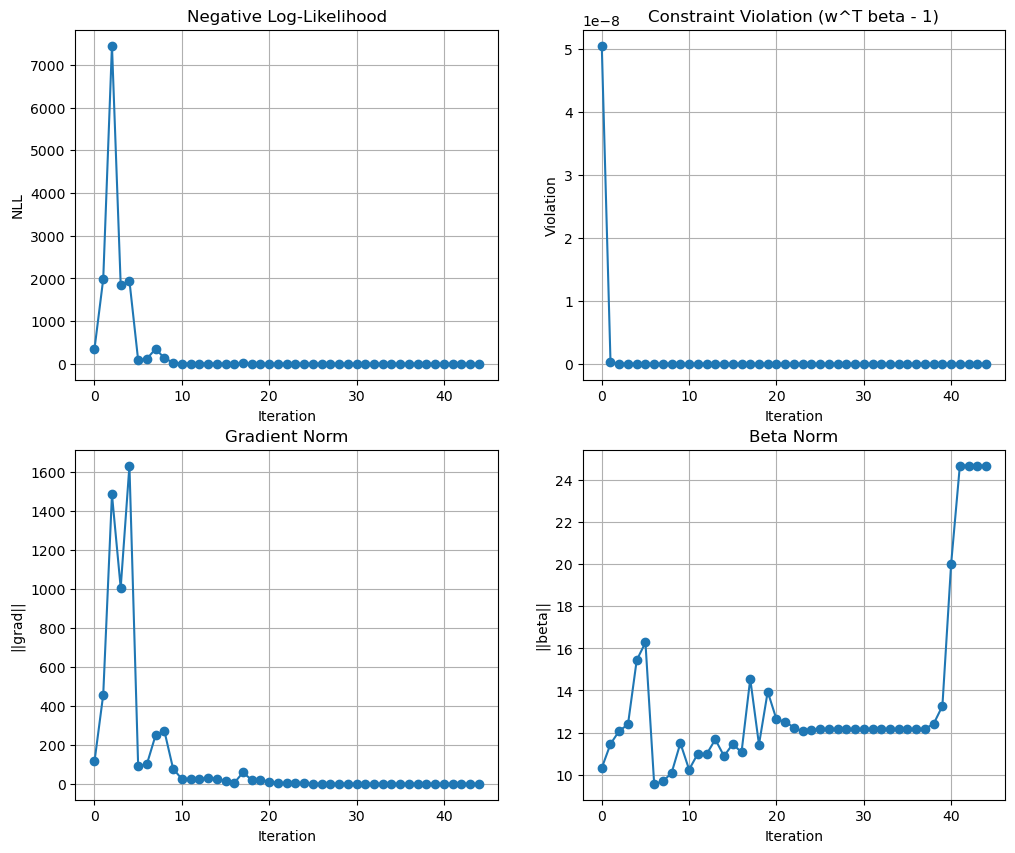

In [137]:
c_hat, c_one_step, info = run_single_experiment(setup_dict, diagnostics=True)

## Simulation

In [129]:
N_sim = 100
plug_in_estimates = np.zeros(N_sim, dtype=float)
one_step_estimates = np.zeros(N_sim, dtype=float)

for sim in range(N_sim):
    print(f"Simulation {sim+1}/{N_sim}")
    c_hat, c_one_step = run_single_experiment(setup_dict, 
                                               diagnostics=False)
    plug_in_estimates[sim] = c_hat
    one_step_estimates[sim] = c_one_step

print("\nResults:")
print(f"Plug-in estimates: mean={plug_in_estimates.mean():.4f}, median={np.median(plug_in_estimates):.4f}, bias={plug_in_estimates.mean() - setup_dict['c']:.4f}, std={plug_in_estimates.std():.4f}")
print(f"One-step estimates: mean={one_step_estimates.mean():.4f}, median={np.median(one_step_estimates):.4f}, bias={one_step_estimates.mean() - setup_dict['c']:.4f}, std={one_step_estimates.std():.4f}")
print(f"True c: {setup_dict['c']}")

Simulation 1/100
Simulation 2/100
Simulation 3/100
Simulation 4/100
Simulation 5/100
Simulation 6/100
Simulation 7/100
Simulation 8/100
Simulation 9/100
Simulation 10/100
Simulation 11/100
Simulation 12/100
Simulation 13/100
Simulation 14/100
Simulation 15/100
Simulation 16/100
Simulation 17/100
Simulation 18/100
Simulation 19/100
Simulation 20/100
Simulation 21/100
Simulation 22/100
Simulation 23/100
Simulation 24/100
Simulation 25/100
Simulation 26/100
Simulation 27/100
Simulation 28/100
Simulation 29/100
Simulation 30/100
Simulation 31/100
Simulation 32/100
Simulation 33/100
Simulation 34/100
Simulation 35/100
Simulation 36/100
Simulation 37/100
Simulation 38/100
Simulation 39/100
Simulation 40/100
Simulation 41/100
Simulation 42/100
Simulation 43/100
Simulation 44/100
Simulation 45/100
Simulation 46/100
Simulation 47/100
Simulation 48/100
Simulation 49/100
Simulation 50/100
Simulation 51/100
Simulation 52/100
Simulation 53/100
Simulation 54/100
Simulation 55/100
Simulation 56/100
S

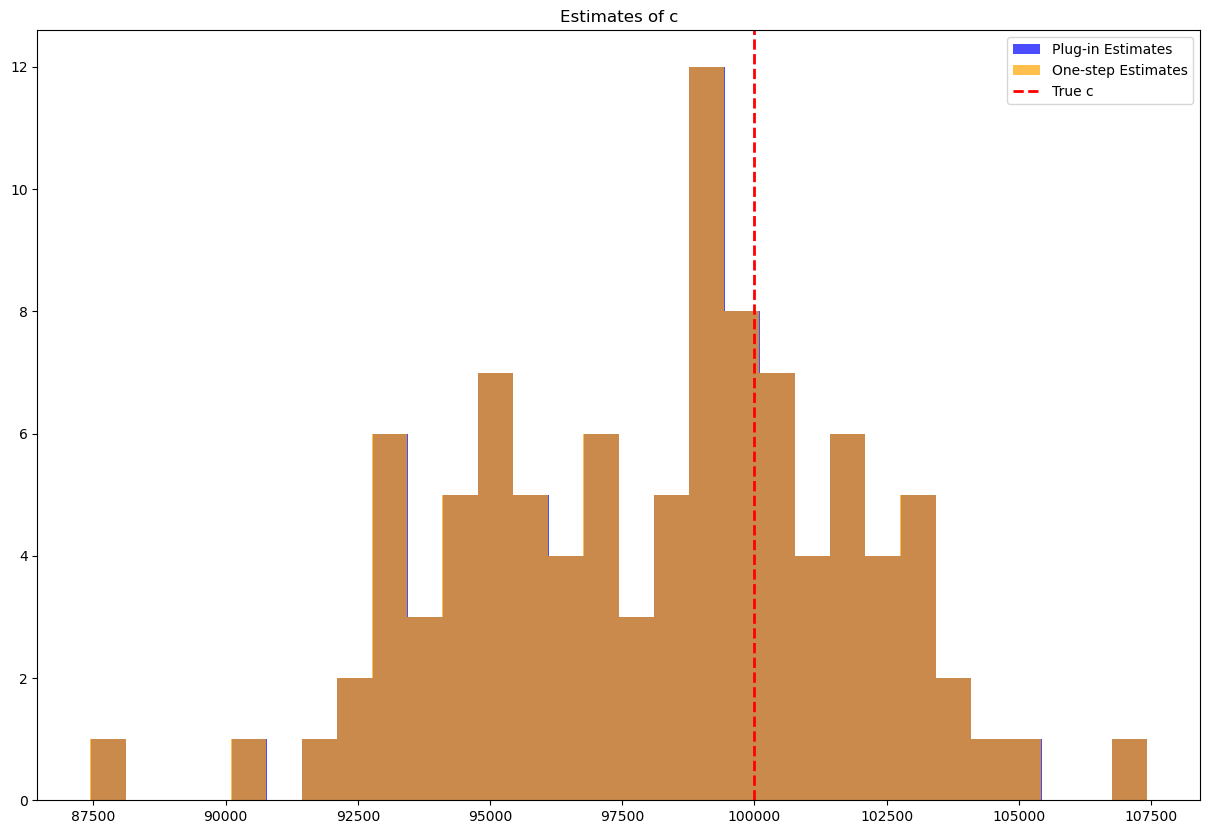

In [130]:
# plot the histograms of the estimates
plt.figure(figsize=(15,10))
plt.hist(plug_in_estimates, bins=30, alpha=0.7, color='blue', label='Plug-in Estimates')
plt.hist(one_step_estimates, bins=30, alpha=0.7, color='orange', label='One-step Estimates')
plt.axvline(setup_dict['c'], color='red', linestyle='dashed', linewidth=2, label='True c')
plt.title("Estimates of c")
plt.legend()

In [287]:
import csv, os, pickle, uuid

log_path = os.path.join(os.path.dirname(os.path.abspath("__file__")), "simulation_results", "experiment-log.csv")
pkl_dir = os.path.join(os.path.dirname(os.path.abspath("__file__")), "simulation_results", "real-model-demo")
os.makedirs(pkl_dir, exist_ok=True)

run_id = uuid.uuid4().hex[:8]

# Find all unpicklable keys
bad_keys = set()
for k, v in setup_dict.items():
    try:
        pickle.dumps(v)
    except Exception as e:
        print(f"Cannot pickle '{k}': {e}")
        bad_keys.add(k)

setup_dict_to_save = {k: v for k, v in setup_dict.items() if k not in bad_keys}

pkl_path = os.path.join(pkl_dir, f"run_{run_id}.pkl")
with open(pkl_path, "wb") as pkl_file:
    pickle.dump({
        "setup_dict": setup_dict_to_save,
        "plug_in_estimates": plug_in_estimates,
        "one_step_estimates": one_step_estimates,
    }, pkl_file)

row = {
    "run_id": run_id,
    "PDF": setup_dict["PDF"],
    "c": setup_dict["c"],
    "gV": setup_dict["gV"],
    "data_var": setup_dict["data_var"],
    "degree": setup_dict["degree"],
    "M": setup_dict["M"],
    "opt": setup_dict["opt"],
    "c_opt": setup_dict["c_opt"],
    "beta_opt": setup_dict["beta_opt"],
    "Lambda": setup_dict["Lambda"],
    "c0": setup_dict["c0"],
    "Q2_min": setup_dict["Q2_min"],
    "Q2_max": setup_dict["Q2_max"],
    "nonneg_beta": setup_dict["nonneg_beta"],
    "parametrize": setup_dict["parametrize"],
    "N_sim": N_sim,
    "plugin_mean": plug_in_estimates.mean(),
    "plugin_median": np.median(plug_in_estimates),
    "plugin_bias": plug_in_estimates.mean() - setup_dict["c"],
    "plugin_std": plug_in_estimates.std(),
    "one_step_mean": one_step_estimates.mean(),
    "one_step_median": np.median(one_step_estimates),
    "one_step_bias": one_step_estimates.mean() - setup_dict["c"],
    "one_step_std": one_step_estimates.std(),
    "notes": "",
}

fieldnames = list(row.keys())
write_header = not os.path.exists(log_path) or os.path.getsize(log_path) == 0

with open(log_path, "a", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=fieldnames)
    if write_header:
        writer.writeheader()
    writer.writerow(row)

print(f"Excluded keys: {bad_keys}")
print(f"run_id: {run_id}")
print(f"CSV:    {log_path}")
print(f"Pickle: {pkl_path}")

Cannot pickle 'alpha_s': self._ptr cannot be converted to a Python object for pickling
Cannot pickle 'klin': Can't pickle local object 'setup_experiment.<locals>.<lambda>'
Cannot pickle 'kquad': Can't pickle local object 'setup_experiment.<locals>.<lambda>'
Excluded keys: {'kquad', 'alpha_s', 'klin'}
run_id: c39597db
CSV:    /mnt/c/Users/huans/OneDrive/CMU/Research/PDF/codes/simulation_results/experiment-log.csv
Pickle: /mnt/c/Users/huans/OneDrive/CMU/Research/PDF/codes/simulation_results/real-model-demo/run_c39597db.pkl
